In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import sys
import torch
import pandas as pd
import numpy as np
import sklearn
import transformers

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Transformers:", transformers.__version__)

print("\nGPU Available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Device:", device)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch: 2.14.1+cpu
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Transformers: 5.22.1

GPU Available: False
Device: cpu


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/TrustFact")
WEEK6 = ROOT / "results" / "week6"

folders = [
    "calibration",
    "figures",
    "metrics",
    "explainability",
    "robustness",
    "models",
    "predictions",
    "backend"
]

assert ROOT.exists(), "TrustFact folder not found"

for folder in folders:
    path = WEEK6 / folder
    path.mkdir(parents=True, exist_ok=True)
    print("Ready:", path)

print("\nWeek 6 setup completed.")

Ready: /content/drive/MyDrive/TrustFact/results/week6/calibration
Ready: /content/drive/MyDrive/TrustFact/results/week6/figures
Ready: /content/drive/MyDrive/TrustFact/results/week6/metrics
Ready: /content/drive/MyDrive/TrustFact/results/week6/explainability
Ready: /content/drive/MyDrive/TrustFact/results/week6/robustness
Ready: /content/drive/MyDrive/TrustFact/results/week6/models
Ready: /content/drive/MyDrive/TrustFact/results/week6/predictions
Ready: /content/drive/MyDrive/TrustFact/results/week6/backend

Week 6 setup completed.


In [ ]:
import json

print("=" * 70)
print("1. DATASET FILES")
print("=" * 70)

for path in sorted(ROOT.rglob("*.tsv")):
    print(path.relative_to(ROOT))

print("\n" + "=" * 70)
print("2. TRANSFORMER MODEL CHECKPOINTS")
print("=" * 70)

for path in sorted(ROOT.rglob("config.json")):
    try:
        with open(path, "r") as f:
            config = json.load(f)

        model_dir = path.parent

        weights = (
            list(model_dir.glob("*.safetensors")) +
            list(model_dir.glob("pytorch_model*.bin"))
        )

        print("\nPath:", model_dir.relative_to(ROOT))
        print("Model type:", config.get("model_type", "Unknown"))
        print("Label mapping:", config.get("id2label", "Unknown"))
        print("Weights found:", bool(weights))

    except Exception as e:
        print("Error:", path, str(e))

print("\n" + "=" * 70)
print("3. TRADITIONAL MACHINE LEARNING MODELS")
print("=" * 70)

for path in sorted(ROOT.rglob("*.joblib")):
    print(path.relative_to(ROOT))

print("\n" + "=" * 70)
print("4. PREVIOUS EXPERIMENTAL RESULTS")
print("=" * 70)

for path in sorted(ROOT.rglob("*.csv")):
    if "data/raw" not in path.as_posix():
        print(path.relative_to(ROOT))

print("\nFile inspection completed.")

1. DATASET FILES
data/raw/liar/test.tsv
data/raw/liar/train.tsv
data/raw/liar/valid.tsv

2. TRANSFORMER MODEL CHECKPOINTS

Path: distilbert_v1
Model type: distilbert
Label mapping: {'0': 'pants-fire', '1': 'false', '2': 'barely-true', '3': 'half-true', '4': 'mostly-true', '5': 'true'}
Weights found: True

Path: results/week4/distilbert/best_model
Model type: distilbert
Label mapping: {'0': 'pants-fire', '1': 'false', '2': 'barely-true', '3': 'half-true', '4': 'mostly-true', '5': 'true'}
Weights found: True

Path: results/week4/distilbert/checkpoints/checkpoint-1280
Model type: distilbert
Label mapping: {'0': 'pants-fire', '1': 'false', '2': 'barely-true', '3': 'half-true', '4': 'mostly-true', '5': 'true'}
Weights found: True

Path: results/week4/distilbert/checkpoints/checkpoint-1920
Model type: distilbert
Label mapping: {'0': 'pants-fire', '1': 'false', '2': 'barely-true', '3': 'half-true', '4': 'mostly-true', '5': 'true'}
Weights found: True

Path: results/week4/distilbert/weighted_c

In [ ]:
DATA_DIR = ROOT / "data" / "raw" / "liar"

LABELS = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

LABEL2ID = {
    label: i for i, label in enumerate(LABELS)
}

ID2LABEL = {
    i: label for label, i in LABEL2ID.items()
}

def load_liar(filename):
    df = pd.read_csv(
        DATA_DIR / filename,
        sep="\t",
        header=None
    )

    df = df.iloc[:, [0, 1, 2]].copy()

    df.columns = [
        "statement_id",
        "label",
        "statement"
    ]

    assert df["statement"].notna().all(), \
        "Missing statements detected"

    df["statement"] = df["statement"].astype(str)

    df["label_id"] = df["label"].map(LABEL2ID)

    assert df["label_id"].notna().all(), \
        "Unknown labels detected"

    df["label_id"] = df["label_id"].astype(int)

    return df

train_df = load_liar("train.tsv")
valid_df = load_liar("valid.tsv")
test_df = load_liar("test.tsv")

print("Dataset successfully loaded")
print("=" * 60)

print("Training samples:", len(train_df))
print("Validation samples:", len(valid_df))
print("Test samples:", len(test_df))

print("\nTotal samples:",
      len(train_df) + len(valid_df) + len(test_df))

print("\nLabel mapping:")
print(LABEL2ID)

print("\nValidation sample:")
display(valid_df.head())

print("\nMissing values:")
print(valid_df.isna().sum())

Dataset successfully loaded
Training samples: 10240
Validation samples: 1284
Test samples: 1267

Total samples: 12791

Label mapping:
{'pants-fire': 0, 'false': 1, 'barely-true': 2, 'half-true': 3, 'mostly-true': 4, 'true': 5}

Validation sample:


,statement_id,label,statement,label_id
0,12134.json,barely-true,We have less Americans working now than in the...,2
1,238.json,pants-fire,"When Obama was sworn into office, he DID NOT u...",0
2,7891.json,false,Says Having organizations parading as being so...,1
3,8169.json,half-true,Says nearly half of Oregons children are poor.,3
4,929.json,half-true,On attacks by Republicans that various program...,3



Missing values:
statement_id    0
label           0
statement       0
label_id        0
dtype: int64


,Training,Validation,Testing
label,,,
pants-fire,839,116,92
false,1995,263,249
barely-true,1654,237,212
half-true,2114,248,265
mostly-true,1962,251,241
true,1676,169,208


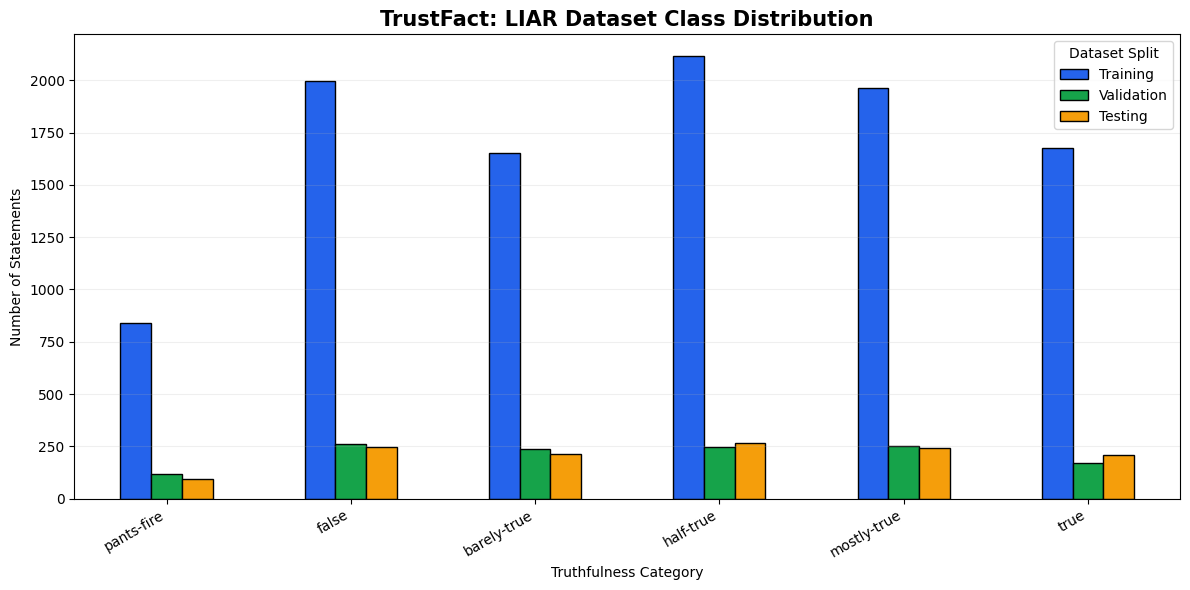

Dataset distribution saved successfully.


In [ ]:
import matplotlib.pyplot as plt

distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": valid_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).reindex(LABELS)

display(distribution)

distribution.to_csv(
    WEEK6 / "metrics" / "dataset_distribution.csv"
)

ax = distribution.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#2563eb", "#16a34a", "#f59e0b"],
    edgecolor="black"
)

plt.title(
    "TrustFact: LIAR Dataset Class Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Truthfulness Category")
plt.ylabel("Number of Statements")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" / "dataset_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dataset distribution saved successfully.")

In [ ]:
MODEL_PATHS = {
    "DistilBERT_V1":
        ROOT / "distilbert_v1",

    "DistilBERT_Week4_Best":
        ROOT / "results/week4/distilbert/best_model",

    "DistilBERT_Week4_1280":
        ROOT / "results/week4/distilbert/checkpoints/checkpoint-1280",

    "DistilBERT_Week4_1920":
        ROOT / "results/week4/distilbert/checkpoints/checkpoint-1920",

    "DistilBERT_Weighted_640":
        ROOT / "results/week4/distilbert/weighted_checkpoints/checkpoint-640",

    "DistilBERT_Weighted_1280":
        ROOT / "results/week4/distilbert/weighted_checkpoints/checkpoint-1280"
}

available_models = {}

for name, path in MODEL_PATHS.items():

    weights = (
        list(path.glob("*.safetensors")) +
        list(path.glob("pytorch_model*.bin"))
    )

    if path.exists() and weights:

        available_models[name] = path

        print(f"\n{name}")
        print("Path:", path)

        for weight in weights:
            print(
                "Weight file:",
                weight.name,
                "| Size:",
                round(weight.stat().st_size / (1024**2), 2),
                "MB"
            )

    else:
        print(f"\n{name}: UNAVAILABLE")

print("\nTotal candidate models:", len(available_models))


DistilBERT_V1
Path: /content/drive/MyDrive/TrustFact/distilbert_v1
Weight file: model.safetensors | Size: 255.44 MB

DistilBERT_Week4_Best
Path: /content/drive/MyDrive/TrustFact/results/week4/distilbert/best_model
Weight file: model.safetensors | Size: 255.44 MB

DistilBERT_Week4_1280
Path: /content/drive/MyDrive/TrustFact/results/week4/distilbert/checkpoints/checkpoint-1280
Weight file: model.safetensors | Size: 255.44 MB

DistilBERT_Week4_1920
Path: /content/drive/MyDrive/TrustFact/results/week4/distilbert/checkpoints/checkpoint-1920
Weight file: model.safetensors | Size: 255.44 MB

DistilBERT_Weighted_640
Path: /content/drive/MyDrive/TrustFact/results/week4/distilbert/weighted_checkpoints/checkpoint-640
Weight file: model.safetensors | Size: 255.44 MB

DistilBERT_Weighted_1280
Path: /content/drive/MyDrive/TrustFact/results/week4/distilbert/weighted_checkpoints/checkpoint-1280
Weight file: model.safetensors | Size: 255.44 MB

Total candidate models: 6


In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

import gc

verified_models = {}

sample_text = "The United States has 50 states."

for name, path in available_models.items():

    print("\n" + "=" * 60)
    print("Checking:", name)

    model = None
    tokenizer = None
    inputs = None
    outputs = None

    try:

        tokenizer = AutoTokenizer.from_pretrained(
            str(path),
            local_files_only=True
        )

        model = AutoModelForSequenceClassification.from_pretrained(
            str(path),
            local_files_only=True
        )

        assert model.config.num_labels == 6

        mapping = {
            int(k): v
            for k, v in model.config.id2label.items()
        }

        assert mapping == ID2LABEL, "Label mapping mismatch"

        model.to(device)
        model.eval()

        inputs = tokenizer(
            sample_text,
            return_tensors="pt",
            truncation=True,
            max_length=128
        ).to(device)

        with torch.inference_mode():
            outputs = model(**inputs)

        assert outputs.logits.shape == (1, 6)
        assert torch.isfinite(outputs.logits).all().item()

        print("Model loaded successfully")
        print("Number of labels:", model.config.num_labels)
        print("Inference output:", outputs.logits.shape)
        print("Status: PASSED")

        verified_models[name] = path

    except Exception as e:

        print("Status: FAILED")
        print("Error:", str(e))

    finally:

        del model, tokenizer, inputs, outputs
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("\n" + "=" * 60)
print("VERIFICATION SUMMARY")
print("=" * 60)

for name in verified_models:
    print("PASSED:", name)

print("\nTotal verified models:", len(verified_models))


Checking: DistilBERT_V1


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully
Number of labels: 6
Inference output: torch.Size([1, 6])
Status: PASSED

Checking: DistilBERT_Week4_Best


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully
Number of labels: 6
Inference output: torch.Size([1, 6])
Status: PASSED

Checking: DistilBERT_Week4_1280


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully
Number of labels: 6
Inference output: torch.Size([1, 6])
Status: PASSED

Checking: DistilBERT_Weighted_1280


Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

Model loaded successfully
Number of labels: 6
Inference output: torch.Size([1, 6])
Status: PASSED

VERIFICATION SUMMARY
PASSED: DistilBERT_V1
PASSED: DistilBERT_Week4_Best
PASSED: DistilBERT_Week4_1280
PASSED: DistilBERT_Week4_1920
PASSED: DistilBERT_Weighted_640
PASSED: DistilBERT_Weighted_1280

Total verified models: 6


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    log_loss
)

from tqdm.auto import tqdm
from scipy.special import softmax

BATCH_SIZE = 32
MAX_LENGTH = 128
NUM_CLASSES = 6

y_true = valid_df["label_id"].to_numpy()

def evaluate_calibration(y_true, probabilities, n_bins=15):

    confidences = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)
    correctness = (predictions == y_true).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):

        if i == 0:
            mask = (
                (confidences >= bin_edges[i]) &
                (confidences <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidences > bin_edges[i]) &
                (confidences <= bin_edges[i + 1])
            )

        if mask.any():

            bin_accuracy = correctness[mask].mean()
            bin_confidence = confidences[mask].mean()

            ece += (
                mask.mean() *
                abs(bin_accuracy - bin_confidence)
            )

    one_hot = np.eye(NUM_CLASSES)[y_true]

    brier = np.mean(
        np.sum((probabilities - one_hot) ** 2, axis=1)
    )

    nll = log_loss(
        y_true,
        probabilities,
        labels=list(range(NUM_CLASSES))
    )

    return {
        "Mean_Confidence": confidences.mean(),
        "ECE": ece,
        "NLL": nll,
        "Brier_Score": brier
    }


def calculate_metrics(y_true, predictions, probabilities):

    metrics = {
        "Accuracy": accuracy_score(y_true, predictions),

        "Macro_Precision": precision_score(
            y_true, predictions,
            average="macro",
            labels=list(range(NUM_CLASSES)),
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y_true, predictions,
            average="macro",
            labels=list(range(NUM_CLASSES)),
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_true, predictions,
            average="macro",
            labels=list(range(NUM_CLASSES)),
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y_true, predictions,
            average="weighted",
            zero_division=0
        )
    }

    metrics.update(
        evaluate_calibration(y_true, probabilities)
    )

    return metrics

print("Evaluation functions ready.")

Evaluation functions ready.


In [ ]:
all_results = []

texts = valid_df["statement"].tolist()

for name, path in verified_models.items():

    print("\n" + "=" * 70)
    print("Evaluating:", name)
    print("=" * 70)

    tokenizer = AutoTokenizer.from_pretrained(
        str(path),
        local_files_only=True
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        str(path),
        local_files_only=True
    )

    model.to(device)
    model.eval()

    all_logits = []

    for start in tqdm(
        range(0, len(texts), BATCH_SIZE),
        desc=name
    ):

        batch_texts = texts[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():

            outputs = model(**inputs)

            logits = outputs.logits.detach().cpu().numpy()

        all_logits.append(logits)

    all_logits = np.concatenate(all_logits, axis=0)

    assert all_logits.shape == (len(valid_df), NUM_CLASSES)
    assert np.isfinite(all_logits).all()

    probabilities = softmax(
        all_logits,
        axis=1
    )

    predictions = probabilities.argmax(axis=1)

    metrics = calculate_metrics(
        y_true,
        predictions,
        probabilities
    )

    metrics["Model"] = name

    all_results.append(metrics)

    # Save raw logits for temperature scaling
    np.save(
        WEEK6 / "predictions" / f"{name}_logits.npy",
        all_logits
    )

    # Save prediction probabilities
    np.save(
        WEEK6 / "predictions" / f"{name}_probabilities.npy",
        probabilities
    )

    # Save individual predictions
    prediction_df = valid_df.copy()

    prediction_df["predicted_id"] = predictions

    prediction_df["predicted_label"] = [
        ID2LABEL[int(p)] for p in predictions
    ]

    prediction_df["confidence"] = probabilities.max(axis=1)

    prediction_df["correct"] = predictions == y_true

    for i, label in enumerate(LABELS):
        prediction_df[f"prob_{label}"] = probabilities[:, i]

    prediction_df.to_csv(
        WEEK6 / "predictions" / f"{name}_predictions.csv",
        index=False
    )

    # Save classification report
    report = classification_report(
        y_true,
        predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        WEEK6 / "metrics" / f"{name}_classification_report.csv"
    )

    for metric, value in metrics.items():

        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    print("Results saved successfully.")

    del model, tokenizer, inputs, outputs

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll transformer evaluations completed.")


Evaluating: DistilBERT_V1


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT_V1:   0%|          | 0/41 [00:00<?, ?it/s]

Accuracy: 0.2773
Macro_Precision: 0.2906
Macro_Recall: 0.2725
Macro_F1: 0.2742
Weighted_F1: 0.2751
Mean_Confidence: 0.3389
ECE: 0.0664
NLL: 1.6853
Brier_Score: 0.8022
Results saved successfully.

Evaluating: DistilBERT_Week4_Best


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT_Week4_Best:   0%|          | 0/41 [00:00<?, ?it/s]

... (9 outputs left out)

Accuracy: 0.2648
Macro_Precision: 0.2656
Macro_Recall: 0.2647
Macro_F1: 0.2575
Weighted_F1: 0.2568
Mean_Confidence: 0.2532
ECE: 0.0176
NLL: 1.6912
Brier_Score: 0.8020
Results saved successfully.

Evaluating: DistilBERT_Weighted_1280


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT_Weighted_1280:   0%|          | 0/41 [00:00<?, ?it/s]

Accuracy: 0.2632
Macro_Precision: 0.2677
Macro_Recall: 0.2842
Macro_F1: 0.2623
Weighted_F1: 0.2536
Mean_Confidence: 0.3049
ECE: 0.0428
NLL: 1.6787
Brier_Score: 0.8008
Results saved successfully.

All transformer evaluations completed.


In [ ]:
comparison_df = pd.DataFrame(all_results)

columns = [
    "Model",
    "Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Weighted_F1",
    "Mean_Confidence",
    "ECE",
    "NLL",
    "Brier_Score"
]

comparison_df = comparison_df[columns]

comparison_df = comparison_df.sort_values(
    by=["Macro_F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(
    WEEK6 / "metrics" / "transformer_model_comparison.csv",
    index=False
)

display(comparison_df.round(4))

best_transformer = comparison_df.iloc[0]

print("\nBEST TRANSFORMER MODEL")
print("=" * 60)

print("Model:", best_transformer["Model"])
print("Accuracy:", round(best_transformer["Accuracy"], 4))
print("Macro-F1:", round(best_transformer["Macro_F1"], 4))
print("ECE:", round(best_transformer["ECE"], 4))
print("NLL:", round(best_transformer["NLL"], 4))
print("Brier Score:", round(best_transformer["Brier_Score"], 4))

print("\nComparison saved successfully.")

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Mean_Confidence,ECE,NLL,Brier_Score
0,DistilBERT_V1,0.2773,0.2906,0.2725,0.2742,0.2751,0.3389,0.0664,1.6853,0.8022
1,DistilBERT_Weighted_1280,0.2632,0.2677,0.2842,0.2623,0.2536,0.3049,0.0428,1.6787,0.8008
2,DistilBERT_Weighted_640,0.2648,0.2656,0.2647,0.2575,0.2568,0.2532,0.0176,1.6912,0.8020
3,DistilBERT_Week4_Best,0.2617,0.2709,0.2557,0.2553,0.2576,0.3479,0.0876,1.7138,0.8119
4,DistilBERT_Week4_1920,0.2617,0.2709,0.2557,0.2553,0.2576,0.3479,0.0876,1.7138,0.8119
5,DistilBERT_Week4_1280,0.2508,0.2625,0.2399,0.2439,0.2480,0.3087,0.0614,1.6850,0.8023



BEST TRANSFORMER MODEL
Model: DistilBERT_V1
Accuracy: 0.2773
Macro-F1: 0.2742
ECE: 0.0664
NLL: 1.6853
Brier Score: 0.8022

Comparison saved successfully.


In [ ]:
import joblib

ML_MODEL_PATHS = {
    "Logistic_Regression":
        ROOT / "results/week4/logistic_regression_pipeline.joblib",

    "Tuned_Logistic_Regression":
        ROOT / "results/week4/best_tuned_lr.joblib",

    "Linear_SVM":
        ROOT / "results/week4/linear_svm_pipeline.joblib"
}

ml_results = []

X_valid = valid_df["statement"].tolist()

def normalize_label(value):

    if isinstance(value, (int, np.integer)):
        return int(value)

    value = str(value)

    if value in LABEL2ID:
        return LABEL2ID[value]

    if value.isdigit():
        return int(value)

    raise ValueError(f"Unknown label: {value}")


for name, path in ML_MODEL_PATHS.items():

    print("\n" + "=" * 60)
    print("Evaluating:", name)

    try:

        pipeline = joblib.load(path)

        raw_predictions = pipeline.predict(X_valid)

        predictions = np.array([
            normalize_label(p)
            for p in raw_predictions
        ])

        assert np.isin(
            predictions,
            range(NUM_CLASSES)
        ).all()

        metrics = {
            "Model": name,

            "Accuracy": accuracy_score(
                y_true, predictions
            ),

            "Macro_Precision": precision_score(
                y_true, predictions,
                average="macro",
                labels=list(range(NUM_CLASSES)),
                zero_division=0
            ),

            "Macro_Recall": recall_score(
                y_true, predictions,
                average="macro",
                labels=list(range(NUM_CLASSES)),
                zero_division=0
            ),

            "Macro_F1": f1_score(
                y_true, predictions,
                average="macro",
                labels=list(range(NUM_CLASSES)),
                zero_division=0
            ),

            "Weighted_F1": f1_score(
                y_true, predictions,
                average="weighted",
                zero_division=0
            )
        }

        prediction_df = valid_df.copy()

        prediction_df["predicted_id"] = predictions

        prediction_df["predicted_label"] = [
            ID2LABEL[int(p)] for p in predictions
        ]

        prediction_df["correct"] = predictions == y_true

        # Evaluate probability metrics when available
        if hasattr(pipeline, "predict_proba"):

            raw_probabilities = pipeline.predict_proba(
                X_valid
            )

            class_ids = [
                normalize_label(c)
                for c in pipeline.classes_
            ]

            assert sorted(class_ids) == list(
                range(NUM_CLASSES)
            )

            probabilities = np.zeros(
                (len(X_valid), NUM_CLASSES)
            )

            for j, class_id in enumerate(class_ids):

                probabilities[:, class_id] = (
                    raw_probabilities[:, j]
                )

            metrics.update(
                evaluate_calibration(
                    y_true, probabilities
                )
            )

            prediction_df["confidence"] = (
                probabilities.max(axis=1)
            )

            np.save(
                WEEK6 / "predictions" /
                f"{name}_probabilities.npy",
                probabilities
            )

        else:

            metrics.update({
                "Mean_Confidence": np.nan,
                "ECE": np.nan,
                "NLL": np.nan,
                "Brier_Score": np.nan
            })

            print(
                "Probability metrics unavailable."
            )

        prediction_df.to_csv(
            WEEK6 / "predictions" /
            f"{name}_predictions.csv",
            index=False
        )

        report = classification_report(
            y_true,
            predictions,
            labels=list(range(NUM_CLASSES)),
            target_names=LABELS,
            output_dict=True,
            zero_division=0
        )

        pd.DataFrame(report).transpose().to_csv(
            WEEK6 / "metrics" /
            f"{name}_classification_report.csv"
        )

        ml_results.append(metrics)

        for key, value in metrics.items():

            if key != "Model":
                print(f"{key}: {value:.4f}")

        print("Status: PASSED")

    except Exception as e:

        print("Status: FAILED")
        print("Error:", str(e))


ml_comparison_df = pd.DataFrame(ml_results)

ml_comparison_df.to_csv(
    WEEK6 / "metrics" /
    "traditional_model_comparison.csv",
    index=False
)

display(ml_comparison_df.round(4))


Evaluating: Logistic_Regression
Accuracy: 0.2531
Macro_Precision: 0.2739
Macro_Recall: 0.2344
Macro_F1: 0.2324
Weighted_F1: 0.2450
Mean_Confidence: 0.3005
ECE: 0.0475
NLL: 1.7042
Brier_Score: 0.8098
Status: PASSED

Evaluating: Tuned_Logistic_Regression
Accuracy: 0.2671
Macro_Precision: 0.2747
Macro_Recall: 0.2592
Macro_F1: 0.2619
Weighted_F1: 0.2654
Mean_Confidence: 0.4709
ECE: 0.2038
NLL: 1.9309
Brier_Score: 0.8933
Status: PASSED

Evaluating: Linear_SVM
Probability metrics unavailable.
Accuracy: 0.2625
Macro_Precision: 0.2637
Macro_Recall: 0.2567
Macro_F1: 0.2582
Weighted_F1: 0.2616
Mean_Confidence: nan
ECE: nan
NLL: nan
Brier_Score: nan
Status: PASSED


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Mean_Confidence,ECE,NLL,Brier_Score
0,Logistic_Regression,0.2531,0.2739,0.2344,0.2324,0.2450,0.3005,0.0475,1.7042,0.8098
1,Tuned_Logistic_Regression,0.2671,0.2747,0.2592,0.2619,0.2654,0.4709,0.2038,1.9309,0.8933
2,Linear_SVM,0.2625,0.2637,0.2567,0.2582,0.2616,NaN,NaN,NaN,NaN


In [ ]:
final_comparison_df = pd.concat(
    [comparison_df, ml_comparison_df],
    ignore_index=True
)

final_comparison_df = (
    final_comparison_df
    .sort_values(
        by=["Macro_F1", "Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

final_comparison_df.insert(
    0,
    "Rank",
    range(1, len(final_comparison_df) + 1)
)

final_comparison_df.to_csv(
    WEEK6 / "metrics" /
    "complete_model_comparison.csv",
    index=False
)

display(final_comparison_df.round(4))

best_overall = final_comparison_df.iloc[0]

print("\nBEST OVERALL MODEL")
print("=" * 60)

print("Model:", best_overall["Model"])

print(
    "Accuracy:",
    round(best_overall["Accuracy"], 4)
)

print(
    "Macro-F1:",
    round(best_overall["Macro_F1"], 4)
)

print("\nTotal evaluated models:",
      len(final_comparison_df))

,Rank,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Mean_Confidence,ECE,NLL,Brier_Score
0,1,DistilBERT_V1,0.2773,0.2906,0.2725,0.2742,0.2751,0.3389,0.0664,1.6853,0.8022
1,2,DistilBERT_Weighted_1280,0.2632,0.2677,0.2842,0.2623,0.2536,0.3049,0.0428,1.6787,0.8008
2,3,Tuned_Logistic_Regression,0.2671,0.2747,0.2592,0.2619,0.2654,0.4709,0.2038,1.9309,0.8933
3,4,Linear_SVM,0.2625,0.2637,0.2567,0.2582,0.2616,NaN,NaN,NaN,NaN
4,5,DistilBERT_Weighted_640,0.2648,0.2656,0.2647,0.2575,0.2568,0.2532,0.0176,1.6912,0.8020
5,6,DistilBERT_Week4_Best,0.2617,0.2709,0.2557,0.2553,0.2576,0.3479,0.0876,1.7138,0.8119
6,7,DistilBERT_Week4_1920,0.2617,0.2709,0.2557,0.2553,0.2576,0.3479,0.0876,1.7138,0.8119
7,8,DistilBERT_Week4_1280,0.2508,0.2625,0.2399,0.2439,0.2480,0.3087,0.0614,1.6850,0.8023
8,9,Logistic_Regression,0.2531,0.2739,0.2344,0.2324,0.2450,0.3005,0.0475,1.7042,0.8098



BEST OVERALL MODEL
Model: DistilBERT_V1
Accuracy: 0.2773
Macro-F1: 0.2742

Total evaluated models: 9


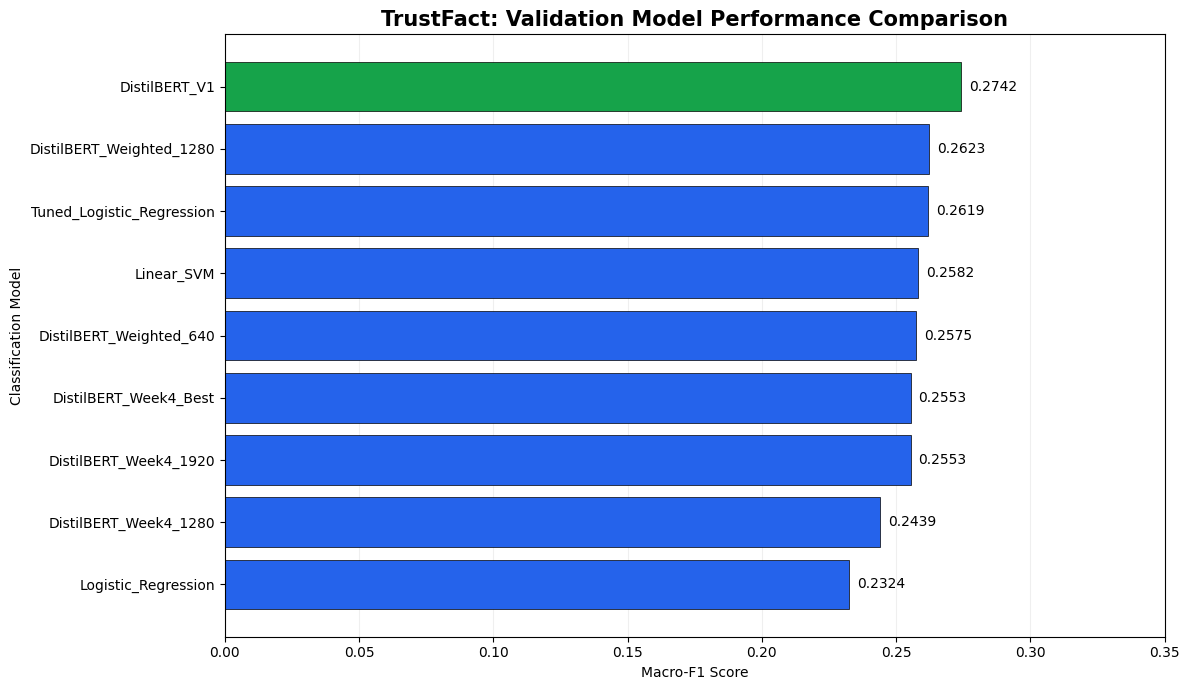

Comparison figure saved successfully.


In [ ]:
plot_df = final_comparison_df.sort_values(
    "Macro_F1",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

colors = [
    "#16a34a" if model == best_overall["Model"]
    else "#2563eb"
    for model in plot_df["Model"]
]

bars = ax.barh(
    plot_df["Model"],
    plot_df["Macro_F1"],
    color=colors,
    edgecolor="black",
    linewidth=0.5
)

for bar in bars:

    value = bar.get_width()

    ax.text(
        value + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "TrustFact: Validation Model Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Macro-F1 Score")
ax.set_ylabel("Classification Model")

ax.set_xlim(
    0,
    max(0.35, plot_df["Macro_F1"].max() + 0.04)
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "complete_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison figure saved successfully.")

In [ ]:
SELECTED_MODEL = "DistilBERT_V1"

SELECTED_MODEL_PATH = verified_models[SELECTED_MODEL]

validation_logits = np.load(
    WEEK6 / "predictions" /
    f"{SELECTED_MODEL}_logits.npy"
)

validation_labels = valid_df["label_id"].to_numpy()

assert validation_logits.shape == (
    len(valid_df), NUM_CLASSES
)

assert np.isfinite(validation_logits).all()

original_probabilities = softmax(
    validation_logits.astype(np.float64),
    axis=1
)

original_predictions = original_probabilities.argmax(axis=1)

original_metrics = calculate_metrics(
    validation_labels,
    original_predictions,
    original_probabilities
)

print("Selected model:", SELECTED_MODEL)
print("Model path:", SELECTED_MODEL_PATH)
print("Logits shape:", validation_logits.shape)
print("Labels shape:", validation_labels.shape)

print("\nUNCALIBRATED MODEL")
print("=" * 60)

for metric, value in original_metrics.items():
    print(f"{metric}: {value:.4f}")

Selected model: DistilBERT_V1
Model path: /content/drive/MyDrive/TrustFact/distilbert_v1
Logits shape: (1284, 6)
Labels shape: (1284,)

UNCALIBRATED MODEL
Accuracy: 0.2773
Macro_Precision: 0.2906
Macro_Recall: 0.2725
Macro_F1: 0.2742
Weighted_F1: 0.2751
Mean_Confidence: 0.3389
ECE: 0.0664
NLL: 1.6853
Brier_Score: 0.8022


In [ ]:
from scipy.optimize import minimize_scalar

def temperature_objective(log_temperature):

    temperature = np.exp(log_temperature)

    scaled_probabilities = softmax(
        validation_logits.astype(np.float64) / temperature,
        axis=1
    )

    loss = log_loss(
        validation_labels,
        scaled_probabilities,
        labels=list(range(NUM_CLASSES))
    )

    return loss


optimization_result = minimize_scalar(
    temperature_objective,
    bounds=(np.log(0.05), np.log(20.0)),
    method="bounded"
)

assert optimization_result.success, \
    "Temperature optimization failed"

optimal_temperature = float(
    np.exp(optimization_result.x)
)

print("Temperature optimization completed.")
print("=" * 60)

print("Original temperature: 1.0000")

print(
    "Optimal temperature:",
    round(optimal_temperature, 6)
)

print(
    "Original NLL:",
    round(temperature_objective(0.0), 6)
)

print(
    "Optimized NLL:",
    round(optimization_result.fun, 6)
)

print(
    "Optimization successful:",
    optimization_result.success
)

Temperature optimization completed.
Original temperature: 1.0000
Optimal temperature: 1.429502
Original NLL: 1.685341
Optimized NLL: 1.667931
Optimization successful: True


In [ ]:
calibrated_probabilities = softmax(
    validation_logits.astype(np.float64) / optimal_temperature,
    axis=1
)

calibrated_predictions = (
    calibrated_probabilities.argmax(axis=1)
)

calibrated_metrics = calculate_metrics(
    validation_labels,
    calibrated_predictions,
    calibrated_probabilities
)

calibration_comparison = pd.DataFrame([
    {
        "Model": "Before Calibration",
        **original_metrics
    },
    {
        "Model": "After Calibration",
        **calibrated_metrics
    }
])

display(calibration_comparison.round(6))

assert np.array_equal(
    original_predictions,
    calibrated_predictions
), "Unexpected prediction changes"

print("\nClass predictions unchanged: True")

print(
    "ECE reduction:",
    round(
        original_metrics["ECE"] -
        calibrated_metrics["ECE"],
        6
    )
)

print(
    "NLL reduction:",
    round(
        original_metrics["NLL"] -
        calibrated_metrics["NLL"],
        6
    )
)

print(
    "Brier score reduction:",
    round(
        original_metrics["Brier_Score"] -
        calibrated_metrics["Brier_Score"],
        6
    )
)

calibration_comparison.to_csv(
    WEEK6 / "calibration" /
    "calibration_comparison.csv",
    index=False
)

np.save(
    WEEK6 / "calibration" /
    "calibrated_validation_probabilities.npy",
    calibrated_probabilities
)

calibration_config = {
    "model": SELECTED_MODEL,
    "model_path": str(
        SELECTED_MODEL_PATH.relative_to(ROOT)
    ),
    "method": "temperature_scaling",
    "temperature": optimal_temperature,
    "optimization_metric": "negative_log_likelihood",
    "calibration_samples": len(validation_labels),
    "max_length": MAX_LENGTH,
    "num_classes": NUM_CLASSES,
    "labels": LABELS
}

with open(
    WEEK6 / "calibration" /
    "calibration_config.json",
    "w"
) as f:
    json.dump(calibration_config, f, indent=4)

print("\nCalibration results saved successfully.")

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Mean_Confidence,ECE,NLL,Brier_Score
0,Before Calibration,0.277259,0.290583,0.272451,0.2742,0.275117,0.338948,0.066366,1.685341,0.802160
1,After Calibration,0.277259,0.290583,0.272451,0.2742,0.275117,0.287428,0.019505,1.667931,0.795373



Class predictions unchanged: True
ECE reduction: 0.046861
NLL reduction: 0.017411
Brier score reduction: 0.006787

Calibration results saved successfully.


In [ ]:
def reliability_data(y_true, probabilities, n_bins=15):

    confidence = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)
    correct = (predictions == y_true).astype(float)

    edges = np.linspace(0, 1, n_bins + 1)

    records = []

    for i in range(n_bins):

        lower = edges[i]
        upper = edges[i + 1]

        if i == 0:
            mask = (
                (confidence >= lower) &
                (confidence <= upper)
            )
        else:
            mask = (
                (confidence > lower) &
                (confidence <= upper)
            )

        count = int(mask.sum())

        records.append({
            "Bin": i + 1,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Bin_Center": (lower + upper) / 2,
            "Count": count,
            "Mean_Confidence":
                confidence[mask].mean()
                if count > 0 else np.nan,
            "Accuracy":
                correct[mask].mean()
                if count > 0 else np.nan
        })

    return pd.DataFrame(records)


before_reliability = reliability_data(
    validation_labels,
    original_probabilities
)

after_reliability = reliability_data(
    validation_labels,
    calibrated_probabilities
)

before_reliability.to_csv(
    WEEK6 / "calibration" /
    "reliability_before.csv",
    index=False
)

after_reliability.to_csv(
    WEEK6 / "calibration" /
    "reliability_after.csv",
    index=False
)

print("Optimal temperature:",
      optimal_temperature)

print("\nBEFORE CALIBRATION")
display(
    before_reliability[
        before_reliability["Count"] > 0
    ].round(4)
)

print("\nAFTER CALIBRATION")
display(
    after_reliability[
        after_reliability["Count"] > 0
    ].round(4)
)

print("Reliability data saved successfully.")

Optimal temperature: 1.429501727746541

BEFORE CALIBRATION


,Bin,Lower_Bound,Upper_Bound,Bin_Center,Count,Mean_Confidence,Accuracy
2,3,0.1333,0.2000,0.1667,2,0.1963,0.0000
3,4,0.2000,0.2667,0.2333,161,0.2451,0.1429
4,5,0.2667,0.3333,0.3000,492,0.3019,0.2602
5,6,0.3333,0.4000,0.3667,418,0.3637,0.3110
6,7,0.4000,0.4667,0.4333,156,0.4247,0.2821
7,8,0.4667,0.5333,0.5000,38,0.4879,0.4737
8,9,0.5333,0.6000,0.5667,9,0.5615,0.7778
9,10,0.6000,0.6667,0.6333,8,0.6181,0.7500



AFTER CALIBRATION


,Bin,Lower_Bound,Upper_Bound,Bin_Center,Count,Mean_Confidence,Accuracy
2,3,0.1333,0.2000,0.1667,9,0.1945,0.1111
3,4,0.2000,0.2667,0.2333,442,0.2428,0.2285
4,5,0.2667,0.3333,0.3000,647,0.2969,0.2844
5,6,0.3333,0.4000,0.3667,166,0.3549,0.3313
6,7,0.4000,0.4667,0.4333,12,0.4297,0.7500
7,8,0.4667,0.5333,0.5000,8,0.4812,0.7500


Reliability data saved successfully.


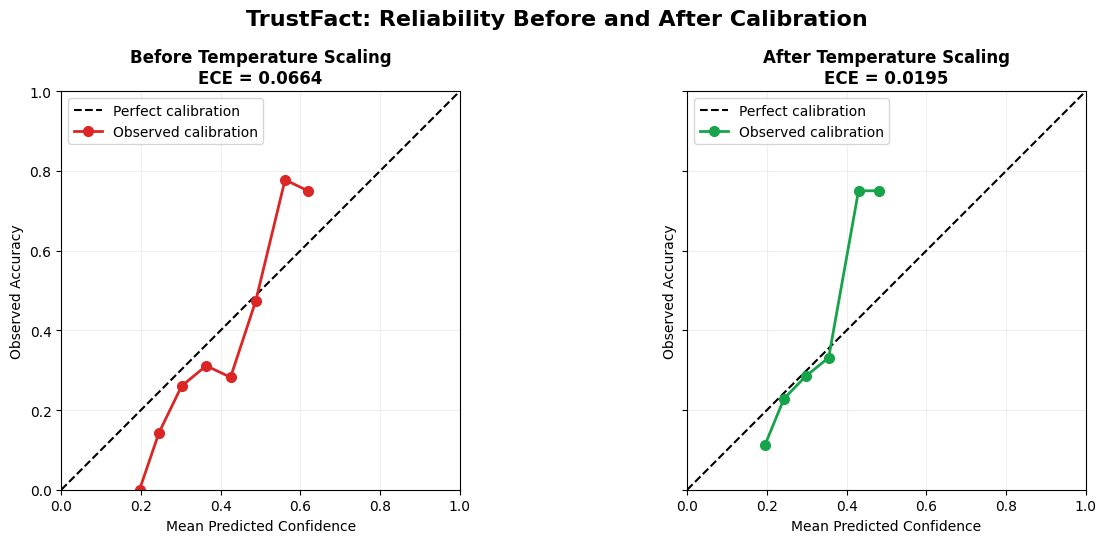

Reliability diagrams saved successfully.


In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharex=True,
    sharey=True
)

configs = [
    (
        axes[0],
        before_reliability,
        original_metrics["ECE"],
        "Before Temperature Scaling",
        "#dc2626"
    ),
    (
        axes[1],
        after_reliability,
        calibrated_metrics["ECE"],
        "After Temperature Scaling",
        "#16a34a"
    )
]

for ax, data, ece, title, color in configs:

    nonempty = data[data["Count"] > 0]

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black",
        linewidth=1.5,
        label="Perfect calibration"
    )

    ax.plot(
        nonempty["Mean_Confidence"],
        nonempty["Accuracy"],
        marker="o",
        markersize=7,
        linewidth=2,
        color=color,
        label="Observed calibration"
    )

    ax.set_title(
        f"{title}\nECE = {ece:.4f}",
        fontweight="bold"
    )

    ax.set_xlabel("Mean Predicted Confidence")
    ax.set_ylabel("Observed Accuracy")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

    ax.legend(loc="upper left")

fig.suptitle(
    "TrustFact: Reliability Before and After Calibration",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "reliability_diagrams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Reliability diagrams saved successfully.")

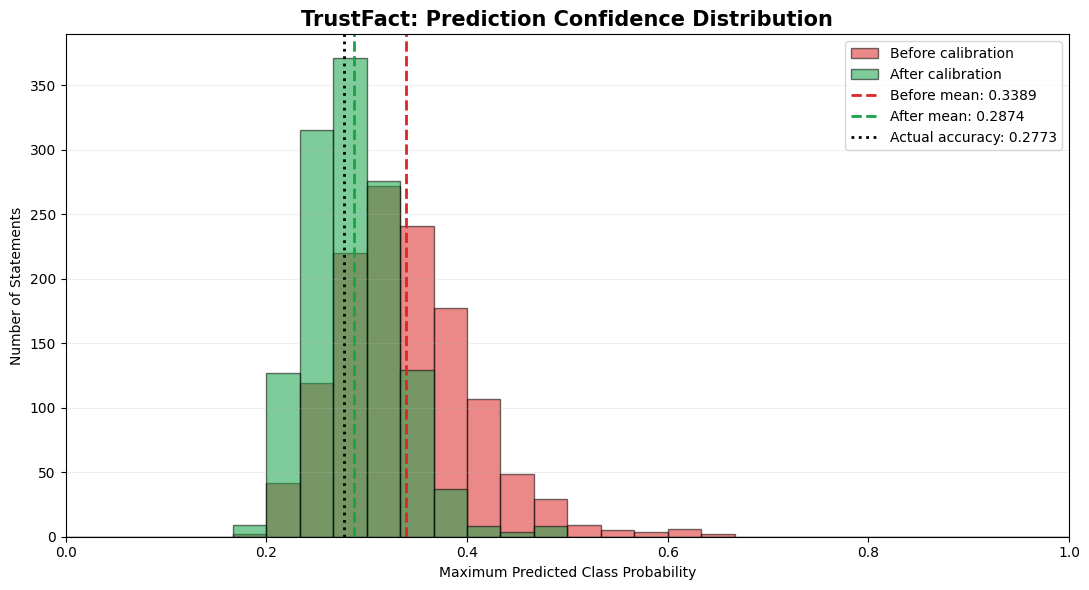

Confidence distribution saved successfully.


In [ ]:
before_confidence = original_probabilities.max(axis=1)

after_confidence = calibrated_probabilities.max(axis=1)

bins = np.linspace(0, 1, 31)

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    before_confidence,
    bins=bins,
    alpha=0.55,
    color="#dc2626",
    edgecolor="black",
    label="Before calibration"
)

ax.hist(
    after_confidence,
    bins=bins,
    alpha=0.55,
    color="#16a34a",
    edgecolor="black",
    label="After calibration"
)

ax.axvline(
    before_confidence.mean(),
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label=f"Before mean: {before_confidence.mean():.4f}"
)

ax.axvline(
    after_confidence.mean(),
    color="#16a34a",
    linestyle="--",
    linewidth=2,
    label=f"After mean: {after_confidence.mean():.4f}"
)

ax.axvline(
    original_metrics["Accuracy"],
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Actual accuracy: {original_metrics['Accuracy']:.4f}"
)

ax.set_title(
    "TrustFact: Prediction Confidence Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Maximum Predicted Class Probability")
ax.set_ylabel("Number of Statements")

ax.set_xlim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "confidence_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confidence distribution saved successfully.")

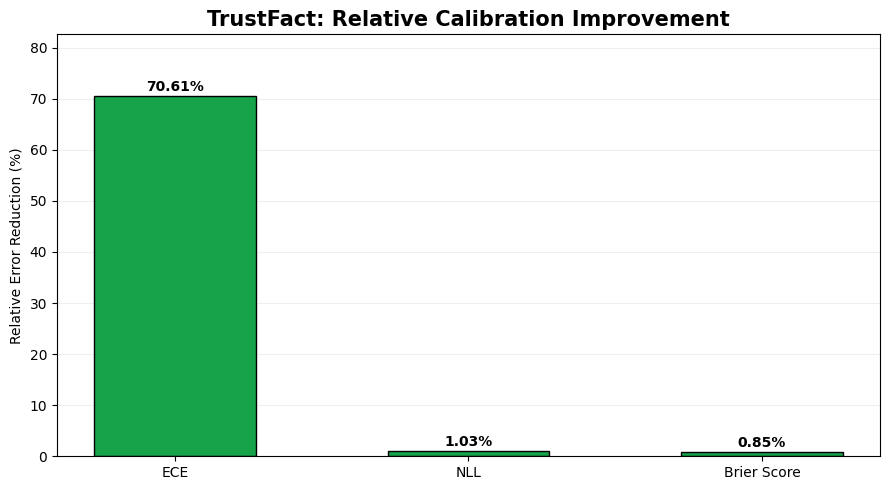

Calibration improvement figure saved.


In [ ]:
metric_names = [
    "ECE",
    "NLL",
    "Brier_Score"
]

improvements = []

for metric in metric_names:

    before = original_metrics[metric]
    after = calibrated_metrics[metric]

    reduction = (
        (before - after) / before
    ) * 100

    improvements.append(reduction)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ["ECE", "NLL", "Brier Score"],
    improvements,
    color="#16a34a",
    edgecolor="black",
    width=0.55
)

for bar, value in zip(bars, improvements):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "TrustFact: Relative Calibration Improvement",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Relative Error Reduction (%)")
ax.set_ylim(0, max(improvements) + 12)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "calibration_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Calibration improvement figure saved.")

In [ ]:
with open(
    WEEK6 / "calibration" / "calibration_config.json",
    "r"
) as f:
    calibration_config = json.load(f)

optimal_temperature = calibration_config["temperature"]

print("Selected model:", calibration_config["model"])
print("Optimal temperature:", optimal_temperature)

print("\nCALIBRATION FILES")
print("=" * 60)

for path in sorted((WEEK6 / "calibration").glob("*")):
    print(path.name)

print("\nFIGURES")
print("=" * 60)

for path in sorted((WEEK6 / "figures").glob("*.png")):
    print(path.name)

print("\nRELIABILITY BIN COUNTS")
display(
    after_reliability[
        after_reliability["Count"] > 0
    ][["Mean_Confidence", "Accuracy", "Count"]]
)

Selected model: DistilBERT_V1
Optimal temperature: 1.429501727746541

CALIBRATION FILES
abstention_config.json
calibrated_validation_probabilities.npy
calibration_comparison.csv
calibration_config.json
reliability_after.csv
reliability_before.csv
test_reliability_after.csv
test_reliability_before.csv

FIGURES
accuracy_coverage_tradeoff.png
calibration_improvement.png
complete_model_comparison.png
confidence_distribution.png
dataset_distribution.png
final_test_confusion_matrix.png
final_test_reliability.png
lime_example_1.png
lime_example_10.png
lime_example_4.png
lime_example_7.png
on_prefix_sensitivity.png
overall_explainability_agreement.png
reliability_diagrams.png
risk_coverage_curve.png
robustness_comparison.png
shap_lime_agreement.png

RELIABILITY BIN COUNTS


,Mean_Confidence,Accuracy,Count
2,0.194503,0.111111,9
3,0.242795,0.228507,442
4,0.296876,0.284389,647
5,0.354857,0.331325,166
6,0.429727,0.750000,12
7,0.481212,0.750000,8


In [ ]:
from scipy.stats import entropy

confidence_scores = calibrated_probabilities.max(axis=1)

predictive_entropy = entropy(
    calibrated_probabilities,
    axis=1
)

normalized_entropy = (
    predictive_entropy / np.log(NUM_CLASSES)
)

sorted_probabilities = np.sort(
    calibrated_probabilities,
    axis=1
)

prediction_margin = (
    sorted_probabilities[:, -1] -
    sorted_probabilities[:, -2]
)

uncertainty_df = valid_df.copy()

uncertainty_df["predicted_label"] = [
    ID2LABEL[int(p)]
    for p in calibrated_predictions
]

uncertainty_df["confidence"] = confidence_scores

uncertainty_df["uncertainty"] = (
    1 - confidence_scores
)

uncertainty_df["predictive_entropy"] = (
    predictive_entropy
)

uncertainty_df["normalized_entropy"] = (
    normalized_entropy
)

uncertainty_df["prediction_margin"] = (
    prediction_margin
)

uncertainty_df["correct"] = (
    calibrated_predictions == validation_labels
)

uncertainty_df.to_csv(
    WEEK6 / "predictions" /
    "validation_uncertainty.csv",
    index=False
)

print("UNCERTAINTY SUMMARY")
print("=" * 60)

display(
    uncertainty_df[
        [
            "confidence",
            "uncertainty",
            "predictive_entropy",
            "normalized_entropy",
            "prediction_margin"
        ]
    ].describe().round(4)
)

print("\nExample predictions:")

display(
    uncertainty_df[
        [
            "statement",
            "label",
            "predicted_label",
            "confidence",
            "normalized_entropy",
            "prediction_margin",
            "correct"
        ]
    ].head(10)
)

print("\nUncertainty results saved successfully.")

UNCERTAINTY SUMMARY


,confidence,uncertainty,predictive_entropy,normalized_entropy,prediction_margin
count,1284.0000,1284.0000,1284.0000,1284.0000,1284.0000
mean,0.2874,0.7126,1.6679,0.9309,0.0599
std,0.0460,0.0460,0.0628,0.0351,0.0507
min,0.1857,0.5023,1.4086,0.7861,0.0000
25%,0.2547,0.6848,1.6291,0.9092,0.0207
50%,0.2829,0.7171,1.6731,0.9338,0.0472
75%,0.3152,0.7453,1.7161,0.9578,0.0861
max,0.4977,0.8143,1.7866,0.9971,0.2797



Example predictions:


,statement,label,predicted_label,confidence,normalized_entropy,prediction_margin,correct
0,We have less Americans working now than in the...,barely-true,mostly-true,0.280057,0.915634,0.022884,False
1,"When Obama was sworn into office, he DID NOT u...",pants-fire,false,0.208220,0.993830,0.025107,False
2,Says Having organizations parading as being so...,false,half-true,0.252944,0.955860,0.015399,False
3,Says nearly half of Oregons children are poor.,half-true,mostly-true,0.290896,0.948352,0.103999,False
4,On attacks by Republicans that various program...,half-true,false,0.285190,0.921340,0.004308,False
5,Says when armed civilians stop mass shootings ...,false,half-true,0.273222,0.942987,0.018049,False
6,Says Tennessee is providing millions of dollar...,true,false,0.243902,0.959650,0.014880,False
7,The health care reform plan would set limits s...,false,half-true,0.254930,0.937550,0.016168,False
8,Says Donald Trump started his career back in 1...,true,true,0.266991,0.939818,0.035556,True
9,Bill White has a long history of trying to lim...,half-true,barely-true,0.270043,0.966185,0.054475,False



Uncertainty results saved successfully.


In [ ]:
thresholds = np.round(
    np.arange(0.15, 0.81, 0.025),
    3
)

abstention_results = []

total_samples = len(validation_labels)

for threshold in thresholds:

    accepted = confidence_scores >= threshold

    accepted_count = int(accepted.sum())

    rejected_count = (
        total_samples - accepted_count
    )

    coverage = accepted_count / total_samples

    abstention_rate = (
        rejected_count / total_samples
    )

    if accepted_count > 0:

        selective_accuracy = accuracy_score(
            validation_labels[accepted],
            calibrated_predictions[accepted]
        )

        selective_f1 = f1_score(
            validation_labels[accepted],
            calibrated_predictions[accepted],
            labels=list(range(NUM_CLASSES)),
            average="macro",
            zero_division=0
        )

        selective_risk = 1 - selective_accuracy

    else:

        selective_accuracy = np.nan
        selective_f1 = np.nan
        selective_risk = np.nan

    abstention_results.append({
        "Threshold": threshold,
        "Accepted": accepted_count,
        "Abstained": rejected_count,
        "Coverage": coverage,
        "Abstention_Rate": abstention_rate,
        "Selective_Accuracy": selective_accuracy,
        "Selective_Macro_F1": selective_f1,
        "Selective_Risk": selective_risk
    })

abstention_df = pd.DataFrame(
    abstention_results
)

abstention_df.to_csv(
    WEEK6 / "metrics" /
    "abstention_threshold_analysis.csv",
    index=False
)

display(abstention_df.round(4))

print("Abstention analysis saved successfully.")

,Threshold,Accepted,Abstained,Coverage,Abstention_Rate,Selective_Accuracy,Selective_Macro_F1,Selective_Risk
0,0.150,1284,0,1.0000,0.0000,0.2773,0.2742,0.7227
1,0.175,1284,0,1.0000,0.0000,0.2773,0.2742,0.7227
2,0.200,1275,9,0.9930,0.0070,0.2784,0.2758,0.7216
3,0.225,1196,88,0.9315,0.0685,0.2868,0.2853,0.7132
4,0.250,1015,269,0.7905,0.2095,0.3034,0.3046,0.6966
5,0.275,740,544,0.5763,0.4237,0.3162,0.3169,0.6838
6,0.300,462,822,0.3598,0.6402,0.3225,0.3112,0.6775
7,0.325,246,1038,0.1916,0.8084,0.3618,0.3479,0.6382
8,0.350,104,1180,0.0810,0.9190,0.4615,0.4035,0.5385
9,0.375,47,1237,0.0366,0.9634,0.5745,0.4873,0.4255


Abstention analysis saved successfully.


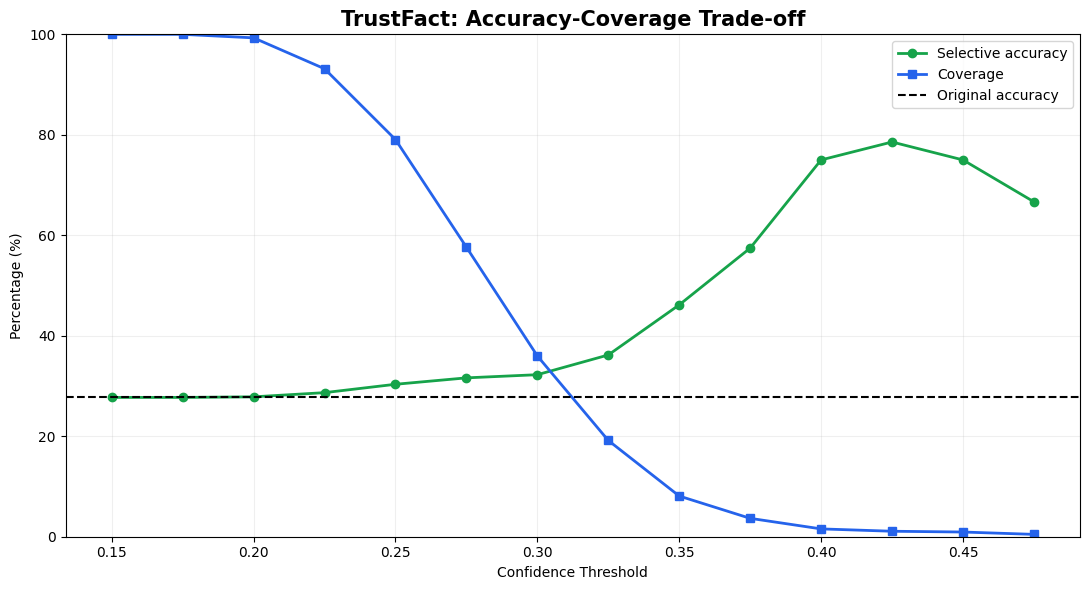

Accuracy-coverage figure saved.


In [ ]:
plot_data = abstention_df[
    abstention_df["Accepted"] > 0
].copy()

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    plot_data["Threshold"],
    plot_data["Selective_Accuracy"] * 100,
    marker="o",
    color="#16a34a",
    linewidth=2,
    label="Selective accuracy"
)

ax.plot(
    plot_data["Threshold"],
    plot_data["Coverage"] * 100,
    marker="s",
    color="#2563eb",
    linewidth=2,
    label="Coverage"
)

ax.axhline(
    original_metrics["Accuracy"] * 100,
    linestyle="--",
    color="black",
    label="Original accuracy"
)

ax.set_title(
    "TrustFact: Accuracy-Coverage Trade-off",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Confidence Threshold")
ax.set_ylabel("Percentage (%)")

ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "accuracy_coverage_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy-coverage figure saved.")

In [ ]:
strategies = {
    "High_Coverage": 0.75,
    "Balanced": 0.50,
    "Conservative": 0.25
}

strategy_results = []

for strategy, min_coverage in strategies.items():

    candidates = abstention_df[
        (abstention_df["Coverage"] >= min_coverage) &
        (abstention_df["Accepted"] > 0)
    ].copy()

    if candidates.empty:
        print(f"No suitable threshold for {strategy}")
        continue

    best = candidates.sort_values(
        by=["Selective_Accuracy", "Coverage"],
        ascending=False
    ).iloc[0]

    strategy_results.append({
        "Strategy": strategy,
        "Threshold": best["Threshold"],
        "Accepted": best["Accepted"],
        "Abstained": best["Abstained"],
        "Coverage": best["Coverage"],
        "Accuracy": best["Selective_Accuracy"],
        "Macro_F1": best["Selective_Macro_F1"],
        "Risk": best["Selective_Risk"]
    })

strategy_df = pd.DataFrame(strategy_results)

display(strategy_df.round(4))

strategy_df.to_csv(
    WEEK6 / "metrics" / "abstention_strategies.csv",
    index=False
)

print("Abstention strategies saved successfully.")

,Strategy,Threshold,Accepted,Abstained,Coverage,Accuracy,Macro_F1,Risk
0,High_Coverage,0.250,1015.0,269.0,0.7905,0.3034,0.3046,0.6966
1,Balanced,0.275,740.0,544.0,0.5763,0.3162,0.3169,0.6838
2,Conservative,0.300,462.0,822.0,0.3598,0.3225,0.3112,0.6775


Abstention strategies saved successfully.


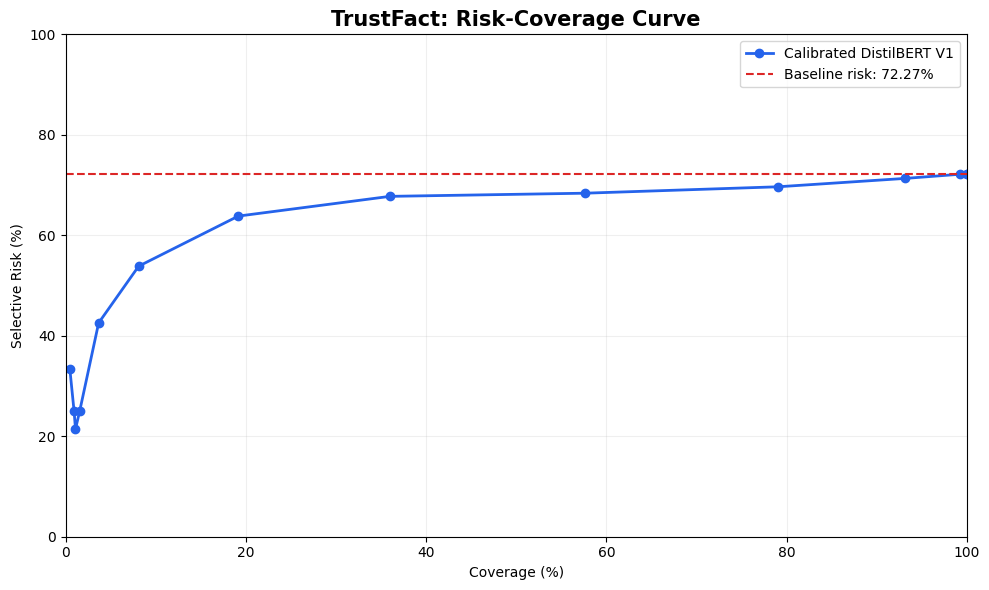

Risk-coverage figure saved successfully.


In [ ]:
risk_df = abstention_df[
    abstention_df["Accepted"] > 0
].sort_values("Coverage")

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    risk_df["Coverage"] * 100,
    risk_df["Selective_Risk"] * 100,
    marker="o",
    color="#2563eb",
    linewidth=2,
    label="Calibrated DistilBERT V1"
)

baseline_risk = 1 - original_metrics["Accuracy"]

ax.axhline(
    baseline_risk * 100,
    color="#dc2626",
    linestyle="--",
    label=f"Baseline risk: {baseline_risk:.2%}"
)

ax.set_title(
    "TrustFact: Risk-Coverage Curve",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Coverage (%)")
ax.set_ylabel("Selective Risk (%)")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" / "risk_coverage_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Risk-coverage figure saved successfully.")

In [ ]:
from sklearn.metrics import roc_auc_score

incorrect = (
    calibrated_predictions != validation_labels
).astype(int)

uncertainty_methods = {
    "Maximum Probability": 1 - confidence_scores,
    "Predictive Entropy": normalized_entropy,
    "Prediction Margin": 1 - prediction_margin
}

uncertainty_results = []

for name, scores in uncertainty_methods.items():

    auc = roc_auc_score(
        incorrect,
        scores
    )

    uncertainty_results.append({
        "Method": name,
        "Error_Detection_AUROC": auc
    })

uncertainty_comparison = pd.DataFrame(
    uncertainty_results
).sort_values(
    "Error_Detection_AUROC",
    ascending=False
)

display(uncertainty_comparison.round(4))

uncertainty_comparison.to_csv(
    WEEK6 / "metrics" /
    "uncertainty_method_comparison.csv",
    index=False
)

print("\nBest uncertainty estimation method:")

print(
    uncertainty_comparison.iloc[0]["Method"]
)

print("Uncertainty comparison saved successfully.")

,Method,Error_Detection_AUROC
1,Predictive Entropy,0.5849
0,Maximum Probability,0.5832
2,Prediction Margin,0.5526



Best uncertainty estimation method:
Predictive Entropy
Uncertainty comparison saved successfully.


In [ ]:
selected_strategy = strategy_df[
    strategy_df["Strategy"] == "Balanced"
].iloc[0]

SELECTED_THRESHOLD = float(
    selected_strategy["Threshold"]
)

abstention_config = {
    "model": SELECTED_MODEL,
    "strategy": "Balanced",
    "confidence_threshold": SELECTED_THRESHOLD,
    "minimum_coverage": 0.50,
    "validation_coverage": float(
        selected_strategy["Coverage"]
    ),
    "validation_selective_accuracy": float(
        selected_strategy["Accuracy"]
    ),
    "temperature": float(optimal_temperature),
    "uncertainty_method": "maximum_probability",
    "status": "experimental"
}

with open(
    WEEK6 / "calibration" / "abstention_config.json",
    "w"
) as f:
    json.dump(abstention_config, f, indent=4)

print(json.dumps(abstention_config, indent=4))

print("\nAbstention configuration saved successfully.")

{
    "model": "DistilBERT_V1",
    "strategy": "Balanced",
    "confidence_threshold": 0.275,
    "minimum_coverage": 0.5,
    "validation_coverage": 0.5763239875389408,
    "validation_selective_accuracy": 0.3162162162162162,
    "temperature": 1.429501727746541,
    "uncertainty_method": "maximum_probability",
    "status": "experimental"
}

Abstention configuration saved successfully.


In [ ]:
%pip install -q shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import shap
import lime

from lime.lime_text import LimeTextExplainer

print("SHAP version:", shap.__version__)
print("LIME successfully imported")
print("GPU available:", torch.cuda.is_available())

print("\nExplainability environment ready.")

SHAP version: 0.54.1
LIME successfully imported
GPU available: False

Explainability environment ready.


In [ ]:
explain_tokenizer = AutoTokenizer.from_pretrained(
    str(SELECTED_MODEL_PATH),
    local_files_only=True
)

explain_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        str(SELECTED_MODEL_PATH),
        local_files_only=True
    )
)

explain_model.to(device)
explain_model.eval()

print("Model:", SELECTED_MODEL)
print("Device:", device)
print("Temperature:", optimal_temperature)
print("Abstention threshold:", SELECTED_THRESHOLD)

print("\nExplainability model loaded.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model: DistilBERT_V1
Device: cpu
Temperature: 1.429501727746541
Abstention threshold: 0.275

Explainability model loaded.


In [ ]:
def predict_calibrated(texts):

    if isinstance(texts, str):
        texts = [texts]

    texts = [str(text) for text in texts]

    results = []

    for start in range(0, len(texts), BATCH_SIZE):

        batch = texts[start:start + BATCH_SIZE]

        inputs = explain_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():

            logits = explain_model(
                **inputs
            ).logits

            probabilities = torch.softmax(
                logits / optimal_temperature,
                dim=1
            )

        results.append(
            probabilities.cpu().numpy()
        )

    return np.concatenate(results, axis=0)


sample_claim = "The United States has 50 states."

sample_probabilities = predict_calibrated(
    [sample_claim]
)[0]

sample_prediction = sample_probabilities.argmax()

print("Statement:", sample_claim)

print(
    "Predicted label:",
    ID2LABEL[int(sample_prediction)]
)

print(
    "Calibrated confidence:",
    round(float(sample_probabilities.max()), 4)
)

print("\nCLASS PROBABILITIES")

display(pd.DataFrame({
    "Label": LABELS,
    "Probability": sample_probabilities
}).round(4))

assert np.isclose(
    sample_probabilities.sum(),
    1.0
)

print("Prediction function verified.")

Statement: The United States has 50 states.
Predicted label: true
Calibrated confidence: 0.3292

CLASS PROBABILITIES


,Label,Probability
0,pants-fire,0.0331
1,false,0.0967
2,barely-true,0.0763
3,half-true,0.1451
4,mostly-true,0.3196
5,true,0.3292


Prediction function verified.


In [ ]:
correct_df = uncertainty_df[
    uncertainty_df["correct"] == True
].copy()

incorrect_df = uncertainty_df[
    uncertainty_df["correct"] == False
].copy()

groups = {
    "High_Confidence_Correct":
        correct_df.nlargest(3, "confidence"),

    "High_Confidence_Incorrect":
        incorrect_df.nlargest(3, "confidence"),

    "Low_Confidence_Correct":
        correct_df.nsmallest(3, "confidence"),

    "Low_Confidence_Incorrect":
        incorrect_df.nsmallest(3, "confidence")
}

selected_examples = []

for group_name, group_df in groups.items():

    group_df = group_df.copy()

    group_df["Explanation_Group"] = group_name

    selected_examples.append(group_df)

explanation_samples = pd.concat(
    selected_examples,
    ignore_index=True
)

explanation_samples.insert(
    0,
    "Example_ID",
    range(1, len(explanation_samples) + 1)
)

explanation_samples.to_csv(
    WEEK6 / "explainability" /
    "selected_explanation_samples.csv",
    index=False
)

display(explanation_samples[
    [
        "Example_ID",
        "Explanation_Group",
        "statement",
        "label",
        "predicted_label",
        "confidence",
        "correct"
    ]
].round(4))

print(
    "\nTotal explanation samples:",
    len(explanation_samples)
)

,Example_ID,Explanation_Group,statement,label,predicted_label,confidence,correct
0,1,High_Confidence_Correct,"On support for Trade Promotion Authority, call...",false,false,0.4895,True
1,2,High_Confidence_Correct,On support of Gov. John Kasichs drilling tax plan,false,false,0.4860,True
2,3,High_Confidence_Correct,On birthright citizenship for illegal immigrants.,false,false,0.4793,True
3,4,High_Confidence_Incorrect,On a single-payer health care system.,half-true,false,0.4977,False
4,5,High_Confidence_Incorrect,On the propriety of budget reconciliation.,half-true,false,0.4807,False
5,6,High_Confidence_Incorrect,On opposition to earmarks,true,false,0.4517,False
6,7,Low_Confidence_Correct,If Barack Obama would apply for a job with the...,false,false,0.1997,True
7,8,Low_Confidence_Correct,TSA WILL ACCEPT DRIVERS PRIV CARDS FOR ID AT T...,true,true,0.2062,True
8,9,Low_Confidence_Correct,"McCain and Bush are millionaires who are ""for ...",mostly-true,mostly-true,0.2088,True
9,10,Low_Confidence_Incorrect,Says a rape kit can be used to clean out women...,pants-fire,barely-true,0.1857,False



Total explanation samples: 12


In [ ]:
shap_masker = shap.maskers.Text(
    explain_tokenizer
)

shap_explainer = shap.Explainer(
    predict_calibrated,
    shap_masker,
    output_names=LABELS,
    algorithm="partition"
)

print("SHAP explainer initialized.")

SHAP explainer initialized.


In [ ]:
shap_results = []
shap_objects = {}

for _, row in tqdm(
    explanation_samples.iterrows(),
    total=len(explanation_samples),
    desc="Generating SHAP explanations"
):

    example_id = int(row["Example_ID"])
    statement = row["statement"]

    predicted_id = LABEL2ID[
        row["predicted_label"]
    ]

    explanation = shap_explainer(
        [statement],
        max_evals=500,
        batch_size=32
    )

    shap_objects[example_id] = explanation

    tokens = explanation.data[0]

    values = explanation.values[
        0, :, predicted_id
    ]

    for token, value in zip(tokens, values):

        token = str(token).strip()

        if not token:
            continue

        shap_results.append({
            "Example_ID": example_id,
            "Group": row["Explanation_Group"],
            "Actual_Label": row["label"],
            "Predicted_Label": row["predicted_label"],
            "Confidence": row["confidence"],
            "Token": token,
            "SHAP_Value": float(value),
            "Absolute_Importance": abs(float(value)),
            "Direction": (
                "Supports"
                if value > 0
                else "Opposes"
                if value < 0
                else "Neutral"
            )
        })

shap_df = pd.DataFrame(shap_results)

shap_df.to_csv(
    WEEK6 / "explainability" /
    "shap_token_attributions.csv",
    index=False
)

print("\nSHAP explanations completed.")
print("Total token attributions:", len(shap_df))

display(shap_df.head(15))

Generating SHAP explanations:   0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/182 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]


PartitionExplainer explainer: 2it [00:31, 31.58s/it]               


  0%|          | 0/342 [00:00<?, ?it/s]


PartitionExplainer explainer: 2it [00:10, 10.61s/it]               


... (4 outputs left out)

  0%|          | 0/498 [00:00<?, ?it/s]


PartitionExplainer explainer: 2it [00:22, 22.25s/it]               



SHAP explanations completed.
Total token attributions: 199


,Example_ID,Group,Actual_Label,Predicted_Label,Confidence,Token,SHAP_Value,Absolute_Importance,Direction
0,1,High_Confidence_Correct,false,false,0.489459,On,0.159734,0.159734,Supports
1,1,High_Confidence_Correct,false,false,0.489459,support,0.045225,0.045225,Supports
2,1,High_Confidence_Correct,false,false,0.489459,for,0.022074,0.022074,Supports
3,1,High_Confidence_Correct,false,false,0.489459,Trade,0.013341,0.013341,Supports
4,1,High_Confidence_Correct,false,false,0.489459,Promotion,0.000708,0.000708,Supports
5,1,High_Confidence_Correct,false,false,0.489459,Authority,0.029302,0.029302,Supports
6,1,High_Confidence_Correct,false,false,0.489459,",",-0.013214,0.013214,Opposes
7,1,High_Confidence_Correct,false,false,0.489459,called,0.016900,0.016900,Supports
8,1,High_Confidence_Correct,false,false,0.489459,fast,0.007905,0.007905,Supports
9,1,High_Confidence_Correct,false,false,0.489459,-,0.009041,0.009041,Supports


In [ ]:
for example_id in [1, 4, 7, 10]:

    row = explanation_samples[
        explanation_samples["Example_ID"] == example_id
    ].iloc[0]

    predicted_id = LABEL2ID[
        row["predicted_label"]
    ]

    print("\n" + "=" * 70)

    print("Example:", example_id)
    print("Group:", row["Explanation_Group"])
    print("Statement:", row["statement"])
    print("Actual label:", row["label"])
    print("Predicted label:", row["predicted_label"])
    print("Confidence:", round(row["confidence"], 4))

    shap.plots.text(
        shap_objects[example_id][
            0, :, predicted_id
        ]
    )


Example: 1
Group: High_Confidence_Correct
Statement: On support for Trade Promotion Authority, calledfast-track
Actual label: false
Predicted label: false
Confidence: 0.4895



Example: 4
Group: High_Confidence_Incorrect
Statement: On a single-payer health care system.
Actual label: half-true
Predicted label: false
Confidence: 0.4977



Example: 7
Group: Low_Confidence_Correct
Statement: If Barack Obama would apply for a job with the FBI or with the Secret Service, he would be disqualified because of his past associations with William Ayers.
Actual label: false
Predicted label: false
Confidence: 0.1997



Example: 10
Group: Low_Confidence_Incorrect
Statement: Says a rape kit can be used to clean out women, basically like dilation and curettage.
Actual label: pants-fire
Predicted label: barely-true
Confidence: 0.1857


In [ ]:
lime_explainer = LimeTextExplainer(
    class_names=LABELS,
    random_state=42
)

print("LIME explainer initialized.")

LIME explainer initialized.


In [ ]:
lime_results = []
lime_objects = {}

for _, row in tqdm(
    explanation_samples.iterrows(),
    total=len(explanation_samples),
    desc="Generating LIME explanations"
):

    example_id = int(row["Example_ID"])

    predicted_id = LABEL2ID[
        row["predicted_label"]
    ]

    explanation = lime_explainer.explain_instance(
        row["statement"],
        predict_calibrated,
        labels=[predicted_id],
        num_features=10,
        num_samples=2000
    )

    lime_objects[example_id] = explanation

    for token, weight in explanation.as_list(
        label=predicted_id
    ):

        lime_results.append({
            "Example_ID": example_id,
            "Group": row["Explanation_Group"],
            "Actual_Label": row["label"],
            "Predicted_Label": row["predicted_label"],
            "Confidence": row["confidence"],
            "Token": token,
            "LIME_Weight": float(weight),
            "Absolute_Importance": abs(float(weight)),
            "Direction": (
                "Supports"
                if weight > 0
                else "Opposes"
                if weight < 0
                else "Neutral"
            )
        })

    explanation.save_to_file(
        str(
            WEEK6 / "explainability" /
            f"lime_example_{example_id}.html"
        ),
        labels=[predicted_id]
    )

lime_df = pd.DataFrame(lime_results)

lime_df.to_csv(
    WEEK6 / "explainability" /
    "lime_token_attributions.csv",
    index=False
)

print("\nLIME explanations completed.")
print("Total token attributions:", len(lime_df))

display(lime_df.head(15))

Generating LIME explanations:   0%|          | 0/12 [00:00<?, ?it/s]


LIME explanations completed.
Total token attributions: 99


,Example_ID,Group,Actual_Label,Predicted_Label,Confidence,Token,LIME_Weight,Absolute_Importance,Direction
0,1,High_Confidence_Correct,false,false,0.489459,On,0.091866,0.091866,Supports
1,1,High_Confidence_Correct,false,false,0.489459,support,0.026166,0.026166,Supports
2,1,High_Confidence_Correct,false,false,0.489459,Promotion,0.015638,0.015638,Supports
3,1,High_Confidence_Correct,false,false,0.489459,Authority,0.009033,0.009033,Supports
4,1,High_Confidence_Correct,false,false,0.489459,Trade,0.008649,0.008649,Supports
5,1,High_Confidence_Correct,false,false,0.489459,track,0.006778,0.006778,Supports
6,1,High_Confidence_Correct,false,false,0.489459,for,-0.003083,0.003083,Opposes
7,1,High_Confidence_Correct,false,false,0.489459,calledfast,-0.000984,0.000984,Opposes
8,2,High_Confidence_Correct,false,false,0.486021,On,0.100555,0.100555,Supports
9,2,High_Confidence_Correct,false,false,0.486021,of,0.011310,0.011310,Supports


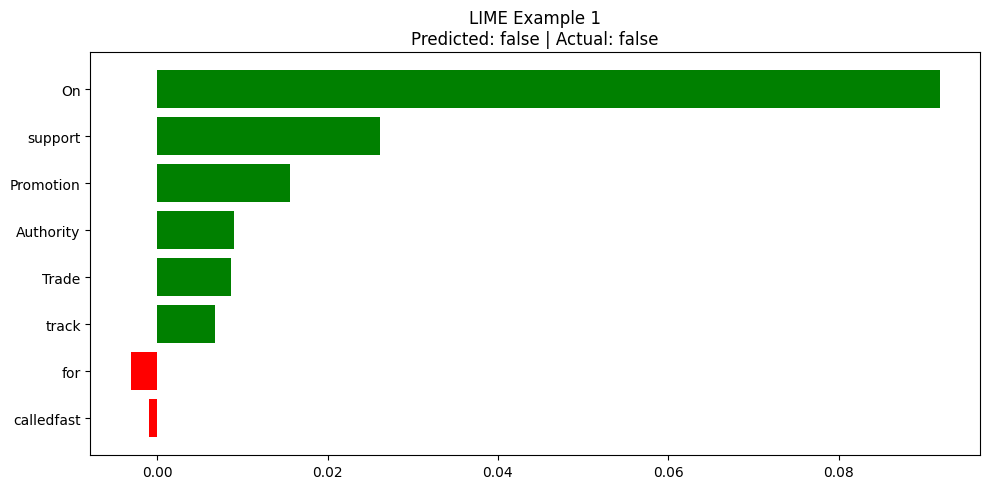

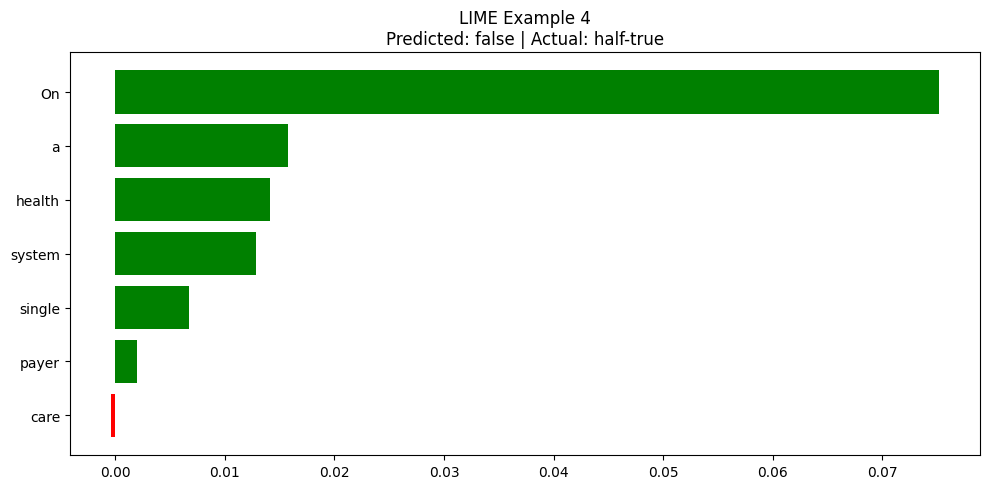

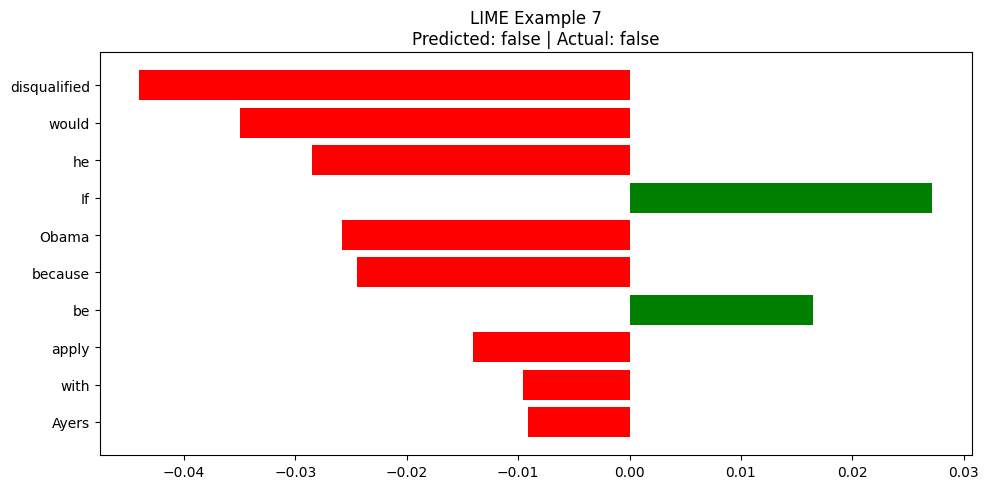

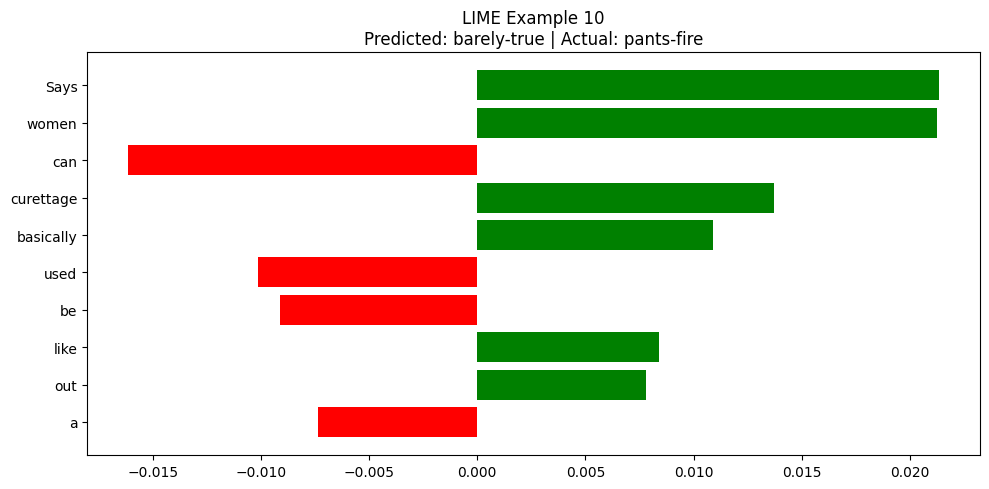

LIME figures saved successfully.


In [ ]:
for example_id in [1, 4, 7, 10]:

    row = explanation_samples[
        explanation_samples["Example_ID"] == example_id
    ].iloc[0]

    predicted_id = LABEL2ID[
        row["predicted_label"]
    ]

    fig = lime_objects[
        example_id
    ].as_pyplot_figure(
        label=predicted_id
    )

    fig.set_size_inches(10, 5)

    plt.title(
        f"LIME Example {example_id}\n"
        f"Predicted: {row['predicted_label']} | "
        f"Actual: {row['label']}"
    )

    plt.tight_layout()

    plt.savefig(
        WEEK6 / "figures" /
        f"lime_example_{example_id}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

print("LIME figures saved successfully.")

In [ ]:
import re

def normalize_token(token):
    token = str(token).lower().strip()

    token = token.replace("##", "")
    token = token.replace("▁", "")
    token = token.replace("Ġ", "")

    token = re.sub(r"[^a-z0-9]", "", token)

    return token


shap_clean = shap_df.copy()
lime_clean = lime_df.copy()

shap_clean["Normalized_Token"] = (
    shap_clean["Token"].apply(normalize_token)
)

lime_clean["Normalized_Token"] = (
    lime_clean["Token"].apply(normalize_token)
)

shap_clean = shap_clean[
    shap_clean["Normalized_Token"] != ""
]

lime_clean = lime_clean[
    lime_clean["Normalized_Token"] != ""
]

shap_aggregated = shap_clean.groupby(
    ["Example_ID", "Normalized_Token"],
    as_index=False
)["SHAP_Value"].sum()

lime_aggregated = lime_clean.groupby(
    ["Example_ID", "Normalized_Token"],
    as_index=False
)["LIME_Weight"].sum()

shap_aggregated["Importance"] = (
    shap_aggregated["SHAP_Value"].abs()
)

lime_aggregated["Importance"] = (
    lime_aggregated["LIME_Weight"].abs()
)

print("SHAP normalized tokens:", len(shap_aggregated))
print("LIME normalized tokens:", len(lime_aggregated))

print("Token normalization completed.")

SHAP normalized tokens: 164
LIME normalized tokens: 99
Token normalization completed.


In [ ]:
TOP_K = 5

agreement_results = []

for _, row in explanation_samples.iterrows():

    example_id = int(row["Example_ID"])

    shap_top = shap_aggregated[
        shap_aggregated["Example_ID"] == example_id
    ].nlargest(TOP_K, "Importance")

    lime_top = lime_aggregated[
        lime_aggregated["Example_ID"] == example_id
    ].nlargest(TOP_K, "Importance")

    shap_tokens = set(
        shap_top["Normalized_Token"]
    )

    lime_tokens = set(
        lime_top["Normalized_Token"]
    )

    intersection = shap_tokens & lime_tokens
    union = shap_tokens | lime_tokens

    jaccard = (
        len(intersection) / len(union)
        if union else np.nan
    )

    overlap = (
        len(intersection) /
        min(len(shap_tokens), len(lime_tokens))
        if shap_tokens and lime_tokens
        else np.nan
    )

    direction_matches = 0
    direction_comparisons = 0

    for token in intersection:

        shap_value = shap_top.loc[
            shap_top["Normalized_Token"] == token,
            "SHAP_Value"
        ].iloc[0]

        lime_value = lime_top.loc[
            lime_top["Normalized_Token"] == token,
            "LIME_Weight"
        ].iloc[0]

        if shap_value != 0 and lime_value != 0:

            direction_comparisons += 1

            if np.sign(shap_value) == np.sign(lime_value):

                direction_matches += 1

    direction_agreement = (
        direction_matches / direction_comparisons
        if direction_comparisons > 0
        else np.nan
    )

    agreement_results.append({
        "Example_ID": example_id,
        "Group": row["Explanation_Group"],
        "Actual_Label": row["label"],
        "Predicted_Label": row["predicted_label"],
        "Confidence": row["confidence"],
        "Jaccard_Similarity": jaccard,
        "Top5_Overlap": overlap,
        "Direction_Agreement": direction_agreement,
        "Shared_Token_Count": len(intersection),
        "Shared_Tokens": ", ".join(sorted(intersection))
    })

agreement_df = pd.DataFrame(agreement_results)

agreement_df.to_csv(
    WEEK6 / "explainability" /
    "shap_lime_agreement.csv",
    index=False
)

display(agreement_df.round(4))

print("\nOVERALL AGREEMENT")
print("=" * 60)

print(
    "Mean Jaccard Similarity:",
    round(agreement_df["Jaccard_Similarity"].mean(), 4)
)

print(
    "Mean Top-5 Overlap:",
    round(agreement_df["Top5_Overlap"].mean(), 4)
)

print(
    "Mean Direction Agreement:",
    round(agreement_df["Direction_Agreement"].mean(), 4)
)

print("Agreement analysis completed.")

,Example_ID,Group,Actual_Label,Predicted_Label,Confidence,Jaccard_Similarity,Top5_Overlap,Direction_Agreement,Shared_Token_Count,Shared_Tokens
0,1,High_Confidence_Correct,false,false,0.4895,0.4286,0.60,1.0000,3,"authority, on, support"
1,2,High_Confidence_Correct,false,false,0.4860,0.4286,0.60,0.6667,3,"of, on, support"
2,3,High_Confidence_Correct,false,false,0.4793,0.2500,0.40,1.0000,2,"immigrants, on"
3,4,High_Confidence_Incorrect,half-true,false,0.4977,0.6667,0.80,1.0000,4,"a, health, on, system"
4,5,High_Confidence_Incorrect,half-true,false,0.4807,0.4286,0.60,1.0000,3,"on, reconciliation, the"
5,6,High_Confidence_Incorrect,true,false,0.4517,0.5000,0.75,1.0000,3,"on, opposition, to"
6,7,Low_Confidence_Correct,false,false,0.1997,0.2500,0.40,1.0000,2,"if, would"
7,8,Low_Confidence_Correct,true,true,0.2062,0.2500,0.40,1.0000,2,"accept, cards"
8,9,Low_Confidence_Correct,mostly-true,mostly-true,0.2088,0.4286,0.60,1.0000,3,"cuts, mccain, who"
9,10,Low_Confidence_Incorrect,pants-fire,barely-true,0.1857,0.4286,0.60,1.0000,3,"can, says, women"



OVERALL AGREEMENT
Mean Jaccard Similarity: 0.38
Mean Top-5 Overlap: 0.5458
Mean Direction Agreement: 0.9722
Agreement analysis completed.


,Jaccard_Similarity,Top5_Overlap,Direction_Agreement
Group,,,
High_Confidence_Correct,0.3690,0.5333,0.8889
High_Confidence_Incorrect,0.5317,0.7167,1.0000
Low_Confidence_Correct,0.3095,0.4667,1.0000
Low_Confidence_Incorrect,0.3095,0.4667,1.0000


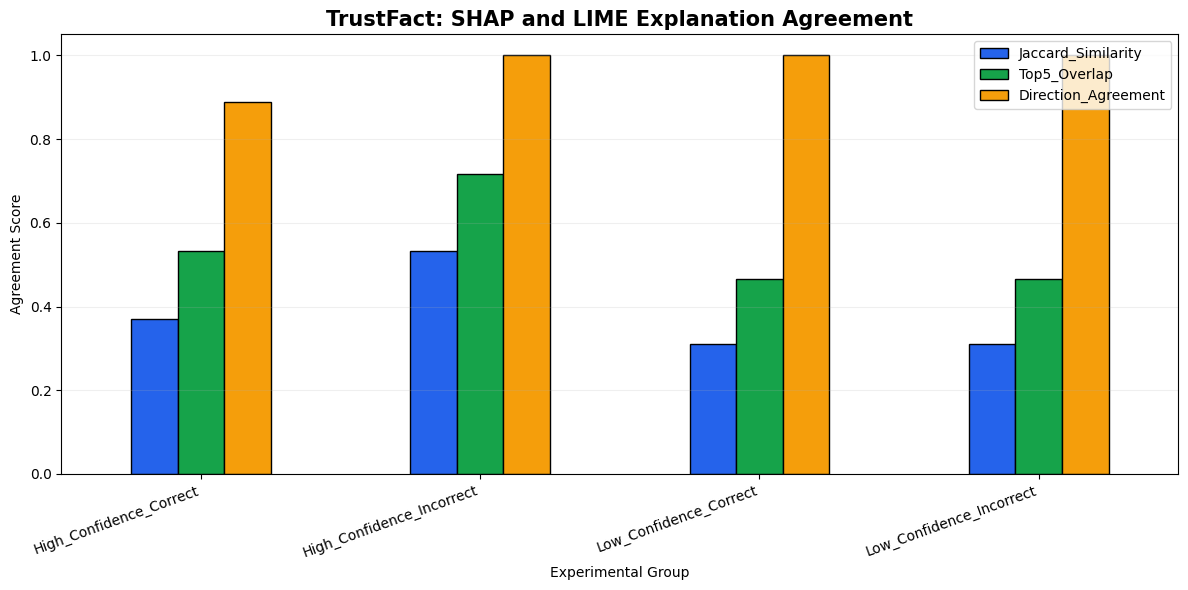

Group agreement figure saved successfully.


In [ ]:
group_agreement = agreement_df.groupby("Group")[
    [
        "Jaccard_Similarity",
        "Top5_Overlap",
        "Direction_Agreement"
    ]
].mean()

display(group_agreement.round(4))

group_agreement.to_csv(
    WEEK6 / "explainability" /
    "group_explanation_agreement.csv"
)

ax = group_agreement.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#2563eb", "#16a34a", "#f59e0b"],
    edgecolor="black"
)

plt.title(
    "TrustFact: SHAP and LIME Explanation Agreement",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Experimental Group")
plt.ylabel("Agreement Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="upper right")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "shap_lime_agreement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Group agreement figure saved successfully.")

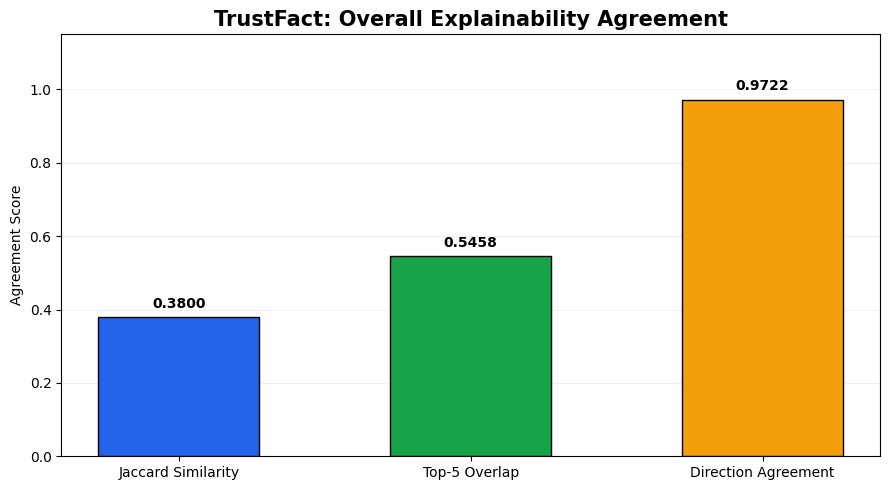

Overall agreement figure saved.


In [ ]:
overall_agreement = agreement_df[
    [
        "Jaccard_Similarity",
        "Top5_Overlap",
        "Direction_Agreement"
    ]
].mean()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ["Jaccard Similarity",
     "Top-5 Overlap",
     "Direction Agreement"],
    overall_agreement.values,
    color=["#2563eb", "#16a34a", "#f59e0b"],
    edgecolor="black",
    width=0.55
)

for bar, value in zip(
    bars,
    overall_agreement.values
):

    if np.isfinite(value):

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.025,
            f"{value:.4f}",
            ha="center",
            fontweight="bold"
        )

ax.set_title(
    "TrustFact: Overall Explainability Agreement",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Agreement Score")
ax.set_ylim(0, 1.15)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "overall_explainability_agreement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Overall agreement figure saved.")

In [ ]:
import re

def lowercase_text(text):
    return text.lower()

def uppercase_text(text):
    return text.upper()

def remove_punctuation(text):
    return re.sub(r"[.,!?;:]", "", text)

def extra_whitespace(text):
    return "  ".join(text.split())

def remove_on_prefix(text):
    return re.sub(
        r"^\s*On\s+",
        "",
        text,
        flags=re.IGNORECASE
    )

perturbations = {
    "Lowercase": lowercase_text,
    "Uppercase": uppercase_text,
    "Punctuation_Removal": remove_punctuation,
    "Extra_Whitespace": extra_whitespace
}

print("Text perturbation functions ready.")

Text perturbation functions ready.


In [ ]:
robustness_results = []
robustness_details = []

original_texts = valid_df["statement"].tolist()

base_predictions = calibrated_predictions

base_confidences = calibrated_probabilities.max(axis=1)

for name, transform in perturbations.items():

    print("\nTesting:", name)

    modified_texts = [
        transform(text)
        for text in original_texts
    ]

    modified_probabilities = predict_calibrated(
        modified_texts
    )

    modified_predictions = (
        modified_probabilities.argmax(axis=1)
    )

    modified_confidences = (
        modified_probabilities.max(axis=1)
    )

    changed = (
        modified_predictions != base_predictions
    )

    confidence_difference = (
        modified_confidences - base_confidences
    )

    accuracy = accuracy_score(
        validation_labels,
        modified_predictions
    )

    macro_f1 = f1_score(
        validation_labels,
        modified_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    robustness_results.append({
        "Perturbation": name,
        "Samples": len(original_texts),
        "Changed_Predictions": int(changed.sum()),
        "Prediction_Flip_Rate": changed.mean(),
        "Prediction_Stability": 1 - changed.mean(),
        "Mean_Confidence_Change":
            confidence_difference.mean(),
        "Mean_Absolute_Confidence_Change":
            np.abs(confidence_difference).mean(),
        "Accuracy": accuracy,
        "Macro_F1": macro_f1
    })

    for i in range(len(original_texts)):

        robustness_details.append({
            "Perturbation": name,
            "Statement_ID":
                valid_df.iloc[i]["statement_id"],
            "Original_Text": original_texts[i],
            "Modified_Text": modified_texts[i],
            "Actual_Label":
                ID2LABEL[int(validation_labels[i])],
            "Original_Prediction":
                ID2LABEL[int(base_predictions[i])],
            "Modified_Prediction":
                ID2LABEL[int(modified_predictions[i])],
            "Original_Confidence":
                base_confidences[i],
            "Modified_Confidence":
                modified_confidences[i],
            "Prediction_Changed": bool(changed[i])
        })

    print("Prediction flip rate:",
          round(changed.mean(), 4))

    print("Accuracy:", round(accuracy, 4))
    print("Macro-F1:", round(macro_f1, 4))


robustness_df = pd.DataFrame(robustness_results)

robustness_details_df = pd.DataFrame(
    robustness_details
)

robustness_df.to_csv(
    WEEK6 / "robustness" /
    "robustness_summary.csv",
    index=False
)

robustness_details_df.to_csv(
    WEEK6 / "robustness" /
    "robustness_detailed_results.csv",
    index=False
)

display(robustness_df.round(4))

print("Robustness experiments completed.")


Testing: Lowercase
Prediction flip rate: 0.0
Accuracy: 0.2773
Macro-F1: 0.2742

Testing: Uppercase
Prediction flip rate: 0.0
Accuracy: 0.2773
Macro-F1: 0.2742

Testing: Punctuation_Removal
Prediction flip rate: 0.1316
Accuracy: 0.2671
Macro-F1: 0.2627

Testing: Extra_Whitespace
Prediction flip rate: 0.0
Accuracy: 0.2773
Macro-F1: 0.2742


,Perturbation,Samples,Changed_Predictions,Prediction_Flip_Rate,Prediction_Stability,Mean_Confidence_Change,Mean_Absolute_Confidence_Change,Accuracy,Macro_F1
0,Lowercase,1284,0,0.0000,1.0000,-0.0000,0.0000,0.2773,0.2742
1,Uppercase,1284,0,0.0000,1.0000,-0.0000,0.0000,0.2773,0.2742
2,Punctuation_Removal,1284,169,0.1316,0.8684,-0.0015,0.0116,0.2671,0.2627
3,Extra_Whitespace,1284,0,0.0000,1.0000,-0.0000,0.0000,0.2773,0.2742


Robustness experiments completed.


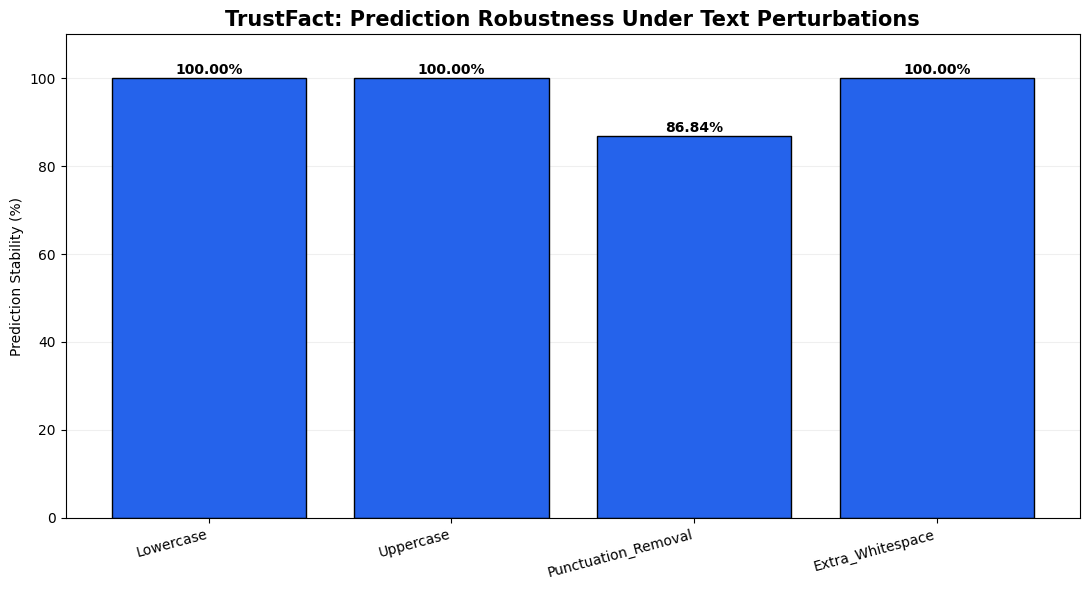

Robustness figure saved successfully.


In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    robustness_df["Perturbation"],
    robustness_df["Prediction_Stability"] * 100,
    color="#2563eb",
    edgecolor="black"
)

for bar in bars:

    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "TrustFact: Prediction Robustness Under Text Perturbations",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Prediction Stability (%)")
ax.set_ylim(0, 110)

plt.xticks(rotation=15, ha="right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "robustness_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Robustness figure saved successfully.")

In [ ]:
on_mask = valid_df["statement"].str.contains(
    r"^\s*On\s+",
    case=False,
    regex=True
).to_numpy()

on_df = valid_df.loc[on_mask].copy()

on_df["predicted_label"] = [
    ID2LABEL[int(p)]
    for p in calibrated_predictions[on_mask]
]

on_df["confidence"] = (
    base_confidences[on_mask]
)

on_df["correct"] = (
    calibrated_predictions[on_mask] ==
    validation_labels[on_mask]
)

print("Total validation statements:",
      len(valid_df))

print("Statements beginning with 'On':",
      len(on_df))

print("\nActual label distribution:")
print(on_df["label"].value_counts())

print("\nPredicted label distribution:")
print(on_df["predicted_label"].value_counts())

bias_summary = []

for name, mask in [
    ("On_Prefix", on_mask),
    ("No_On_Prefix", ~on_mask)
]:

    if not mask.any():
        continue

    bias_summary.append({
        "Group": name,
        "Samples": int(mask.sum()),
        "Actual_False_Rate": np.mean(
            validation_labels[mask] ==
            LABEL2ID["false"]
        ),
        "Predicted_False_Rate": np.mean(
            calibrated_predictions[mask] ==
            LABEL2ID["false"]
        ),
        "Accuracy": np.mean(
            calibrated_predictions[mask] ==
            validation_labels[mask]
        ),
        "Mean_Confidence":
            base_confidences[mask].mean()
    })

bias_summary_df = pd.DataFrame(bias_summary)

display(bias_summary_df.round(4))

bias_summary_df.to_csv(
    WEEK6 / "robustness" /
    "on_prefix_bias_analysis.csv",
    index=False
)

Total validation statements: 1284
Statements beginning with 'On': 17

Actual label distribution:
label
false         10
half-true      5
pants-fire     1
true           1
Name: count, dtype: int64

Predicted label distribution:
predicted_label
false         14
pants-fire     2
half-true      1
Name: count, dtype: int64


,Group,Samples,Actual_False_Rate,Predicted_False_Rate,Accuracy,Mean_Confidence
0,On_Prefix,17,0.5882,0.8235,0.7059,0.4243
1,No_On_Prefix,1267,0.1997,0.2170,0.2715,0.2856


In [ ]:
assert on_mask.any(), "No On-prefix statements found"

on_original_texts = on_df["statement"].tolist()

on_modified_texts = [
    remove_on_prefix(text)
    for text in on_original_texts
]

on_modified_probabilities = predict_calibrated(
    on_modified_texts
)

on_original_predictions = (
    calibrated_predictions[on_mask]
)

on_modified_predictions = (
    on_modified_probabilities.argmax(axis=1)
)

on_original_false_probability = (
    calibrated_probabilities[
        on_mask, LABEL2ID["false"]
    ]
)

on_modified_false_probability = (
    on_modified_probabilities[
        :, LABEL2ID["false"]
    ]
)

on_df["Modified_Statement"] = on_modified_texts

on_df["Modified_Prediction"] = [
    ID2LABEL[int(p)]
    for p in on_modified_predictions
]

on_df["Prediction_Changed"] = (
    on_original_predictions !=
    on_modified_predictions
)

on_df["Original_False_Probability"] = (
    on_original_false_probability
)

on_df["Modified_False_Probability"] = (
    on_modified_false_probability
)

on_df["False_Probability_Change"] = (
    on_modified_false_probability -
    on_original_false_probability
)

print("ON-PREFIX SENSITIVITY RESULTS")
print("=" * 60)

print("Samples:", len(on_df))

print(
    "Prediction flip rate:",
    round(on_df["Prediction_Changed"].mean(), 4)
)

print(
    "Original false prediction rate:",
    round(np.mean(
        on_original_predictions == LABEL2ID["false"]
    ), 4)
)

print(
    "Modified false prediction rate:",
    round(np.mean(
        on_modified_predictions == LABEL2ID["false"]
    ), 4)
)

print(
    "Mean change in false probability:",
    round(on_df["False_Probability_Change"].mean(), 4)
)

display(on_df[
    [
        "statement",
        "Modified_Statement",
        "label",
        "predicted_label",
        "Modified_Prediction",
        "Prediction_Changed"
    ]
].head(15))

on_df.to_csv(
    WEEK6 / "robustness" /
    "on_prefix_sensitivity_results.csv",
    index=False
)

print("Linguistic sensitivity results saved.")

ON-PREFIX SENSITIVITY RESULTS
Samples: 17
Prediction flip rate: 0.1176
Original false prediction rate: 0.8235
Modified false prediction rate: 0.7059
Mean change in false probability: -0.0726


,statement,Modified_Statement,label,predicted_label,Modified_Prediction,Prediction_Changed
4,On attacks by Republicans that various program...,attacks by Republicans that various programs i...,half-true,false,barely-true,True
127,On the propriety of budget reconciliation.,the propriety of budget reconciliation.,half-true,false,false,False
157,On high-speed rail.,high-speed rail.,false,false,false,False
192,On whether state employees should contribute t...,whether state employees should contribute to t...,false,false,false,False
260,"On Medicare for current retirees, hes cutting ...","Medicare for current retirees, hes cutting $71...",half-true,half-true,half-true,False
289,"On climate change, the temperature readings ha...","climate change, the temperature readings have ...",pants-fire,pants-fire,pants-fire,False
302,"On support for Trade Promotion Authority, call...","support for Trade Promotion Authority, calledf...",false,false,false,False
448,On the night of the Wisconsin state Senate vot...,the night of the Wisconsin state Senate vote o...,half-true,pants-fire,pants-fire,False
470,"On the Iraq war, I said it loud and clear, You...","the Iraq war, I said it loud and clear, Youll ...",false,false,false,False
515,On birthright citizenship for illegal immigrants.,birthright citizenship for illegal immigrants.,false,false,false,False


Linguistic sensitivity results saved.


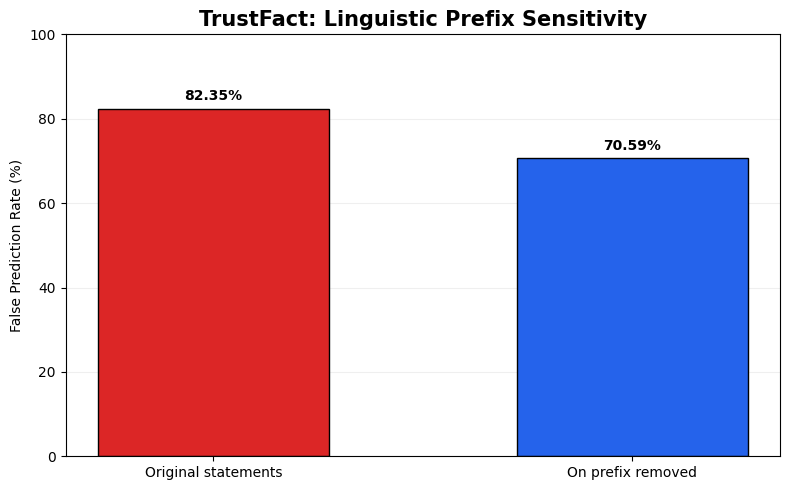

Linguistic sensitivity figure saved.


In [ ]:
false_rates = [
    np.mean(
        on_original_predictions == LABEL2ID["false"]
    ) * 100,

    np.mean(
        on_modified_predictions == LABEL2ID["false"]
    ) * 100
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Original statements", "On prefix removed"],
    false_rates,
    color=["#dc2626", "#2563eb"],
    edgecolor="black",
    width=0.55
)

for bar, value in zip(bars, false_rates):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "TrustFact: Linguistic Prefix Sensitivity",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("False Prediction Rate (%)")
ax.set_ylim(0, 100)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "on_prefix_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Linguistic sensitivity figure saved.")

In [ ]:
with open(
    WEEK6 / "calibration" /
    "calibration_config.json", "r"
) as f:
    calibration_config = json.load(f)

with open(
    WEEK6 / "calibration" /
    "abstention_config.json", "r"
) as f:
    abstention_config = json.load(f)

assert calibration_config["model"] == SELECTED_MODEL
assert abstention_config["model"] == SELECTED_MODEL

assert np.isclose(
    calibration_config["temperature"],
    abstention_config["temperature"]
)

FINAL_TEMPERATURE = float(
    calibration_config["temperature"]
)

FINAL_THRESHOLD = float(
    abstention_config["confidence_threshold"]
)

assert FINAL_TEMPERATURE > 0
assert 0 <= FINAL_THRESHOLD <= 1

final_config = {
    "project": "TrustFact",
    "model": SELECTED_MODEL,
    "model_path": str(
        SELECTED_MODEL_PATH.relative_to(ROOT)
    ),
    "architecture": "DistilBERT",
    "labels": LABELS,
    "num_classes": NUM_CLASSES,
    "max_length": MAX_LENGTH,
    "temperature": FINAL_TEMPERATURE,
    "confidence_threshold": FINAL_THRESHOLD,
    "calibration_method": "temperature_scaling",
    "selection_metric": "validation_macro_f1",
    "explainability_methods": ["SHAP", "LIME"],
    "status": "frozen_for_test_evaluation"
}

with open(
    WEEK6 / "models" / "final_model_config.json",
    "w"
) as f:
    json.dump(final_config, f, indent=4)

print(json.dumps(final_config, indent=4))

print("\nFinal model configuration frozen.")

{
    "project": "TrustFact",
    "model": "DistilBERT_V1",
    "model_path": "distilbert_v1",
    "architecture": "DistilBERT",
    "labels": [
        "pants-fire",
        "false",
        "barely-true",
        "half-true",
        "mostly-true",
        "true"
    ],
    "num_classes": 6,
    "max_length": 128,
    "temperature": 1.429501727746541,
    "confidence_threshold": 0.275,
    "calibration_method": "temperature_scaling",
    "selection_metric": "validation_macro_f1",
    "explainability_methods": [
        "SHAP",
        "LIME"
    ],
    "status": "frozen_for_test_evaluation"
}

Final model configuration frozen.


In [ ]:
test_texts = test_df["statement"].tolist()

test_labels = test_df["label_id"].to_numpy()

test_logits_batches = []

assert SELECTED_MODEL_PATH.exists()

test_tokenizer = AutoTokenizer.from_pretrained(
    str(SELECTED_MODEL_PATH),
    local_files_only=True
)

test_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        str(SELECTED_MODEL_PATH),
        local_files_only=True
    )
)

test_model.to(device)
test_model.eval()

for start in tqdm(
    range(0, len(test_texts), BATCH_SIZE),
    desc="Final test evaluation"
):

    batch = test_texts[
        start:start + BATCH_SIZE
    ]

    inputs = test_tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():

        logits = test_model(**inputs).logits

    test_logits_batches.append(
        logits.cpu().numpy()
    )

test_logits = np.concatenate(
    test_logits_batches,
    axis=0
)

assert test_logits.shape == (
    len(test_df), NUM_CLASSES
)

assert np.isfinite(test_logits).all()

np.save(
    WEEK6 / "predictions" / "final_test_logits.npy",
    test_logits
)

print("\nTest inference completed.")
print("Test samples:", len(test_labels))
print("Logits shape:", test_logits.shape)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Final test evaluation:   0%|          | 0/40 [00:00<?, ?it/s]


Test inference completed.
Test samples: 1267
Logits shape: (1267, 6)


In [ ]:
test_original_probabilities = softmax(
    test_logits.astype(np.float64),
    axis=1
)

test_calibrated_probabilities = softmax(
    test_logits.astype(np.float64) /
    FINAL_TEMPERATURE,
    axis=1
)

test_original_predictions = (
    test_original_probabilities.argmax(axis=1)
)

test_calibrated_predictions = (
    test_calibrated_probabilities.argmax(axis=1)
)

test_before_metrics = calculate_metrics(
    test_labels,
    test_original_predictions,
    test_original_probabilities
)

test_after_metrics = calculate_metrics(
    test_labels,
    test_calibrated_predictions,
    test_calibrated_probabilities
)

test_comparison = pd.DataFrame([
    {
        "Model": "Before Calibration",
        **test_before_metrics
    },
    {
        "Model": "After Calibration",
        **test_after_metrics
    }
])

display(test_comparison.round(6))

assert np.array_equal(
    test_original_predictions,
    test_calibrated_predictions
)

test_comparison.to_csv(
    WEEK6 / "metrics" /
    "final_test_calibration_comparison.csv",
    index=False
)

print("\nECE reduction:")

print(
    test_before_metrics["ECE"] -
    test_after_metrics["ECE"]
)

print("\nFinal test calibration evaluation saved.")

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Mean_Confidence,ECE,NLL,Brier_Score
0,Before Calibration,0.29045,0.290566,0.275304,0.277672,0.286552,0.343429,0.055863,1.670357,0.796962
1,After Calibration,0.29045,0.290566,0.275304,0.277672,0.286552,0.290415,0.008503,1.656235,0.791258



ECE reduction:
0.04736049049475298

Final test calibration evaluation saved.


In [ ]:
test_confidence = (
    test_calibrated_probabilities.max(axis=1)
)

test_accepted = (
    test_confidence >= FINAL_THRESHOLD
)

accepted_count = int(test_accepted.sum())

abstained_count = (
    len(test_labels) - accepted_count
)

test_coverage = test_accepted.mean()

if accepted_count > 0:

    selective_accuracy = accuracy_score(
        test_labels[test_accepted],
        test_calibrated_predictions[test_accepted]
    )

    selective_f1 = f1_score(
        test_labels[test_accepted],
        test_calibrated_predictions[test_accepted],
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

else:

    selective_accuracy = np.nan
    selective_f1 = np.nan

final_abstention_results = {
    "Threshold": FINAL_THRESHOLD,
    "Total_Samples": len(test_labels),
    "Accepted": accepted_count,
    "Abstained": abstained_count,
    "Coverage": test_coverage,
    "Abstention_Rate": 1 - test_coverage,
    "Full_Accuracy":
        test_after_metrics["Accuracy"],
    "Selective_Accuracy": selective_accuracy,
    "Selective_Macro_F1": selective_f1,
    "Selective_Risk": 1 - selective_accuracy
}

final_abstention_df = pd.DataFrame([
    final_abstention_results
])

display(final_abstention_df.round(4))

final_abstention_df.to_csv(
    WEEK6 / "metrics" /
    "final_test_abstention_results.csv",
    index=False
)

print("\nFINAL ABSTENTION RESULTS")
print("=" * 60)

print("Confidence threshold:", FINAL_THRESHOLD)
print("Accepted statements:", accepted_count)
print("Abstained statements:", abstained_count)
print(f"Coverage: {test_coverage:.2%}")
print(f"Selective accuracy: {selective_accuracy:.2%}")
print(f"Selective risk: {1-selective_accuracy:.2%}")

,Threshold,Total_Samples,Accepted,Abstained,Coverage,Abstention_Rate,Full_Accuracy,Selective_Accuracy,Selective_Macro_F1,Selective_Risk
0,0.275,1267,759,508,0.5991,0.4009,0.2904,0.3109,0.2926,0.6891



FINAL ABSTENTION RESULTS
Confidence threshold: 0.275
Accepted statements: 759
Abstained statements: 508
Coverage: 59.91%
Selective accuracy: 31.09%
Selective risk: 68.91%


In [ ]:
final_test_report = classification_report(
    test_labels,
    test_calibrated_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=LABELS,
    output_dict=True,
    zero_division=0
)

final_test_report_df = pd.DataFrame(
    final_test_report
).transpose()

display(final_test_report_df.round(4))

final_test_report_df.to_csv(
    WEEK6 / "metrics" /
    "final_test_classification_report.csv"
)

print("\nFINAL TEST CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        test_labels,
        test_calibrated_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=LABELS,
        digits=4,
        zero_division=0
    )
)

print("Classification report saved successfully.")

,precision,recall,f1-score,support
pants-fire,0.2807,0.1739,0.2148,92.0000
false,0.3080,0.3414,0.3238,249.0000
barely-true,0.3000,0.1840,0.2281,212.0000
half-true,0.2862,0.3509,0.3153,265.0000
mostly-true,0.2657,0.2988,0.2812,241.0000
true,0.3029,0.3029,0.3029,208.0000
accuracy,0.2904,0.2904,0.2904,0.2904
macro avg,0.2906,0.2753,0.2777,1267.0000
weighted avg,0.2912,0.2904,0.2866,1267.0000



FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  pants-fire     0.2807    0.1739    0.2148        92
       false     0.3080    0.3414    0.3238       249
 barely-true     0.3000    0.1840    0.2281       212
   half-true     0.2862    0.3509    0.3153       265
 mostly-true     0.2657    0.2988    0.2812       241
        true     0.3029    0.3029    0.3029       208

    accuracy                         0.2904      1267
   macro avg     0.2906    0.2753    0.2777      1267
weighted avg     0.2912    0.2904    0.2866      1267

Classification report saved successfully.


,pants-fire,false,barely-true,half-true,mostly-true,true
pants-fire,16,30,16,9,13,8
false,13,85,27,55,34,35
barely-true,13,46,39,55,36,23
half-true,7,52,26,93,52,35
mostly-true,4,34,16,71,72,44
true,4,29,6,42,64,63


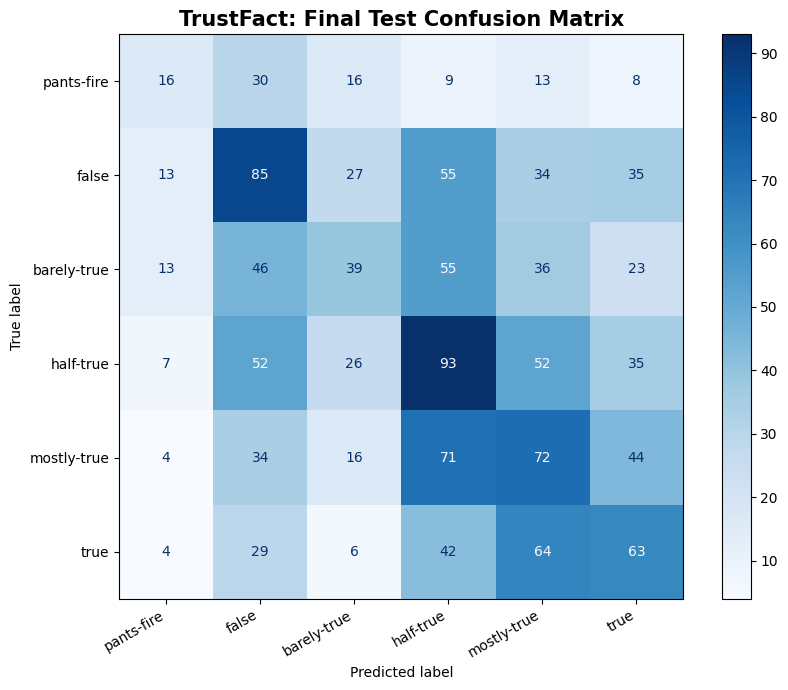

Final confusion matrix saved.


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

final_cm = confusion_matrix(
    test_labels,
    test_calibrated_predictions,
    labels=list(range(NUM_CLASSES))
)

final_cm_df = pd.DataFrame(
    final_cm,
    index=LABELS,
    columns=LABELS
)

display(final_cm_df)

final_cm_df.to_csv(
    WEEK6 / "metrics" /
    "final_test_confusion_matrix.csv"
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=LABELS
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

plt.title(
    "TrustFact: Final Test Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final confusion matrix saved.")

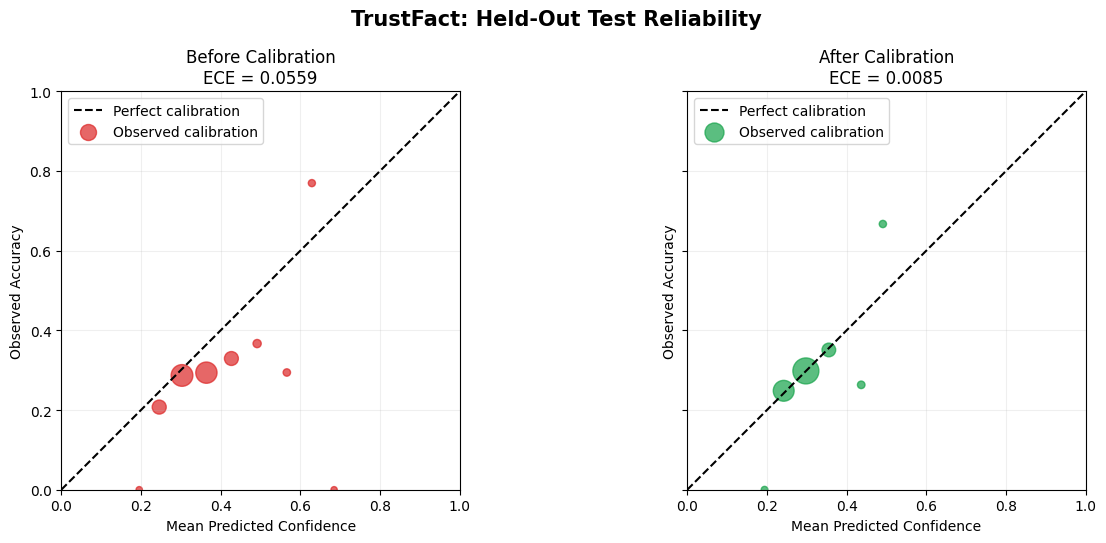

Test reliability diagrams saved.


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Mean_Confidence,ECE,NLL,Brier_Score
0,Before Calibration,0.29045,0.290566,0.275304,0.277672,0.286552,0.343429,0.055863,1.670357,0.796962
1,After Calibration,0.29045,0.290566,0.275304,0.277672,0.286552,0.290415,0.008503,1.656235,0.791258


In [ ]:
test_before_reliability = reliability_data(
    test_labels,
    test_original_probabilities
)

test_after_reliability = reliability_data(
    test_labels,
    test_calibrated_probabilities
)

test_before_reliability.to_csv(
    WEEK6 / "calibration" /
    "test_reliability_before.csv",
    index=False
)

test_after_reliability.to_csv(
    WEEK6 / "calibration" /
    "test_reliability_after.csv",
    index=False
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharex=True,
    sharey=True
)

configs = [
    (
        axes[0],
        test_before_reliability,
        test_before_metrics["ECE"],
        "Before Calibration",
        "#dc2626"
    ),
    (
        axes[1],
        test_after_reliability,
        test_after_metrics["ECE"],
        "After Calibration",
        "#16a34a"
    )
]

for ax, data, ece, title, color in configs:

    nonempty = data[data["Count"] > 0]

    ax.plot(
        [0, 1], [0, 1],
        "k--",
        label="Perfect calibration"
    )

    ax.scatter(
        nonempty["Mean_Confidence"],
        nonempty["Accuracy"],
        s=20 + nonempty["Count"] * 0.5,
        color=color,
        alpha=0.7,
        label="Observed calibration"
    )

    ax.set_title(
        f"{title}\nECE = {ece:.4f}"
    )

    ax.set_xlabel("Mean Predicted Confidence")
    ax.set_ylabel("Observed Accuracy")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(
    "TrustFact: Held-Out Test Reliability",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    WEEK6 / "figures" /
    "final_test_reliability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Test reliability diagrams saved.")

display(test_comparison.round(6))

In [ ]:
final_test_predictions_df = test_df.copy()

final_test_predictions_df["predicted_id"] = (
    test_calibrated_predictions
)

final_test_predictions_df["predicted_label"] = [
    ID2LABEL[int(p)]
    for p in test_calibrated_predictions
]

final_test_predictions_df["original_confidence"] = (
    test_original_probabilities.max(axis=1)
)

final_test_predictions_df["calibrated_confidence"] = (
    test_confidence
)

final_test_predictions_df["correct"] = (
    test_calibrated_predictions == test_labels
)

final_test_predictions_df["normalized_entropy"] = (
    entropy(test_calibrated_probabilities, axis=1)
    / np.log(NUM_CLASSES)
)

final_test_predictions_df["accepted"] = test_accepted

final_test_predictions_df["system_decision"] = np.where(
    test_accepted,
    final_test_predictions_df["predicted_label"],
    "Insufficient Confidence"
)

for i, label in enumerate(LABELS):

    final_test_predictions_df[
        f"prob_{label}"
    ] = test_calibrated_probabilities[:, i]

final_test_predictions_df.to_csv(
    WEEK6 / "predictions" /
    "final_test_predictions.csv",
    index=False
)

display(final_test_predictions_df.head(10))

print(
    "Total test predictions saved:",
    len(final_test_predictions_df)
)

,statement_id,label,statement,label_id,predicted_id,predicted_label,original_confidence,calibrated_confidence,correct,normalized_entropy,accepted,system_decision,prob_pants-fire,prob_false,prob_barely-true,prob_half-true,prob_mostly-true,prob_true
0,11972.json,true,Building a wall on the U.S.-Mexico border will...,5,1,false,0.388563,0.316425,False,0.934116,True,false,0.125530,0.316425,0.196716,0.194339,0.101092,0.065897
1,11685.json,false,Wisconsin is on pace to double the number of l...,1,3,half-true,0.327970,0.279824,False,0.936301,True,half-true,0.042648,0.167096,0.136609,0.279824,0.232337,0.141485
2,11096.json,false,Says John McCain has done nothing to help the ...,1,2,barely-true,0.260832,0.232867,False,0.971759,False,Insufficient Confidence,0.217075,0.203140,0.232867,0.131840,0.101964,0.113114
3,5209.json,half-true,Suzanne Bonamici supports a plan that will cut...,3,2,barely-true,0.367648,0.310081,False,0.904213,True,barely-true,0.249012,0.197373,0.310081,0.125401,0.074312,0.043821
4,9524.json,pants-fire,When asked by a reporter whether hes at the ce...,0,1,false,0.263825,0.232920,False,0.982616,False,Insufficient Confidence,0.126477,0.232920,0.214706,0.156651,0.123575,0.145670
5,5962.json,true,Over the past five years the federal governmen...,5,5,true,0.398785,0.326905,True,0.911442,True,true,0.042704,0.125954,0.097214,0.179981,0.227241,0.326905
6,7070.json,true,Says that Tennessee law requires that schools ...,5,4,mostly-true,0.263100,0.236361,False,0.956234,False,Insufficient Confidence,0.049301,0.164877,0.146106,0.201483,0.236361,0.201873
7,1046.json,barely-true,"Says Vice President Joe Biden ""admits that the...",2,2,barely-true,0.354186,0.297078,True,0.930862,True,barely-true,0.111185,0.184311,0.297078,0.242110,0.101123,0.064193
8,12849.json,true,Donald Trump is against marriage equality. He ...,5,3,half-true,0.295309,0.255559,False,0.962340,False,Insufficient Confidence,0.068088,0.210763,0.168142,0.255559,0.166431,0.131017
9,13270.json,barely-true,We know that more than half of Hillary Clinton...,2,4,mostly-true,0.256641,0.231639,False,0.960969,False,Insufficient Confidence,0.056679,0.147641,0.154283,0.202021,0.231639,0.207737


Total test predictions saved: 1267


In [ ]:
master_summary = {
    "project": "TrustFact",
    "week": 6,
    "selected_model": SELECTED_MODEL,
    "training_samples": len(train_df),
    "validation_samples": len(valid_df),
    "test_samples": len(test_df),

    "model_configuration": final_config,

    "validation_before_calibration": {
        k: float(v)
        for k, v in original_metrics.items()
    },

    "validation_after_calibration": {
        k: float(v)
        for k, v in calibrated_metrics.items()
    },

    "test_before_calibration": {
        k: float(v)
        for k, v in test_before_metrics.items()
    },

    "test_after_calibration": {
        k: float(v)
        for k, v in test_after_metrics.items()
    },

    "test_abstention": final_abstention_results,

    "explainability": {
        "samples": len(explanation_samples),

        "mean_jaccard": float(
            agreement_df["Jaccard_Similarity"].mean()
        ),

        "mean_top5_overlap": float(
            agreement_df["Top5_Overlap"].mean()
        ),

        "mean_direction_agreement": float(
            agreement_df["Direction_Agreement"].mean()
        )
    },

    "linguistic_sensitivity": {
        "samples": len(on_df),

        "prediction_flip_rate": float(
            on_df["Prediction_Changed"].mean()
        ),

        "original_false_rate": float(
            np.mean(
                on_original_predictions ==
                LABEL2ID["false"]
            )
        ),

        "modified_false_rate": float(
            np.mean(
                on_modified_predictions ==
                LABEL2ID["false"]
            )
        ),

        "mean_false_probability_change": float(
            on_df["False_Probability_Change"].mean()
        )
    }
}

def json_converter(obj):

    if isinstance(obj, np.generic):
        return obj.item()

    raise TypeError(
        f"Unsupported type: {type(obj)}"
    )

with open(
    WEEK6 / "metrics" /
    "week6_master_summary.json",
    "w"
) as f:

    json.dump(
        master_summary,
        f,
        indent=4,
        default=json_converter
    )

print(json.dumps(
    master_summary,
    indent=4,
    default=json_converter
))

print("\nWeek 6 master summary saved.")

{
    "project": "TrustFact",
    "week": 6,
    "selected_model": "DistilBERT_V1",
    "training_samples": 10240,
    "validation_samples": 1284,
    "test_samples": 1267,
    "model_configuration": {
        "project": "TrustFact",
        "model": "DistilBERT_V1",
        "model_path": "distilbert_v1",
        "architecture": "DistilBERT",
        "labels": [
            "pants-fire",
            "false",
            "barely-true",
            "half-true",
            "mostly-true",
            "true"
        ],
        "num_classes": 6,
        "max_length": 128,
        "temperature": 1.429501727746541,
        "confidence_threshold": 0.275,
        "calibration_method": "temperature_scaling",
        "selection_metric": "validation_macro_f1",
        "explainability_methods": [
            "SHAP",
            "LIME"
        ],
        "status": "frozen_for_test_evaluation"
    },
    "validation_before_calibration": {
        "Accuracy": 0.2772585669781931,
        "Macro_Precisi

In [ ]:
import shutil

DEPLOYMENT = WEEK6 / "deployment" / "TrustFact_Model"

DEPLOYMENT.mkdir(
    parents=True,
    exist_ok=True
)

deployment_model_dir = DEPLOYMENT / "model"

# Save the verified trained model
test_model.save_pretrained(
    str(deployment_model_dir),
    safe_serialization=True
)

# Save the tokenizer
test_tokenizer.save_pretrained(
    str(deployment_model_dir)
)

# Copy configuration files
files_to_copy = [
    WEEK6 / "models" / "final_model_config.json",

    WEEK6 / "calibration" / "calibration_config.json",

    WEEK6 / "calibration" / "abstention_config.json",

    WEEK6 / "metrics" / "week6_master_summary.json"
]

for source in files_to_copy:

    assert source.exists(), f"Missing: {source}"

    shutil.copy2(
        source,
        DEPLOYMENT / source.name
    )

# Record the verified environment
environment = {
    "python": sys.version,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__
}

with open(
    DEPLOYMENT / "environment.json",
    "w"
) as f:
    json.dump(environment, f, indent=4)

print("DEPLOYMENT PACKAGE")
print("=" * 60)

for path in sorted(DEPLOYMENT.rglob("*")):

    if path.is_file():

        print(
            path.relative_to(DEPLOYMENT),
            "|",
            round(path.stat().st_size / 1024**2, 2),
            "MB"
        )

print("\nDeployment package created successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DEPLOYMENT PACKAGE
abstention_config.json | 0.0 MB
calibration_config.json | 0.0 MB
environment.json | 0.0 MB
final_model_config.json | 0.0 MB
model/config.json | 0.0 MB
model/model.safetensors | 255.44 MB
model/tokenizer.json | 0.68 MB
model/tokenizer_config.json | 0.0 MB
week6_master_summary.json | 0.0 MB

Deployment package created successfully.


In [ ]:
exported_tokenizer = AutoTokenizer.from_pretrained(
    str(deployment_model_dir),
    local_files_only=True
)

exported_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        str(deployment_model_dir),
        local_files_only=True
    )
)

exported_model.to(device)
exported_model.eval()

verification_texts = (
    valid_df["statement"].head(10).tolist()
)

inputs = exported_tokenizer(
    verification_texts,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
).to(device)

with torch.inference_mode():

    exported_logits = (
        exported_model(**inputs)
        .logits.cpu().numpy()
    )

reference_logits = validation_logits[:10]

difference = np.max(
    np.abs(exported_logits - reference_logits)
)

print("Maximum logit difference:", difference)

assert np.allclose(
    exported_logits,
    reference_logits,
    atol=1e-4,
    rtol=1e-4
), "Exported model predictions differ"

print("Exported model verification: PASSED")

del exported_model, exported_tokenizer
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Maximum logit difference: 7.5623393e-07
Exported model verification: PASSED


In [ ]:
ZIP_PATH = shutil.make_archive(
    str(WEEK6 / "deployment" / "TrustFact_Model"),
    "zip",
    root_dir=str(DEPLOYMENT.parent),
    base_dir=DEPLOYMENT.name
)

zip_size = Path(ZIP_PATH).stat().st_size / 1024**2

print("ZIP file:", ZIP_PATH)
print("ZIP size:", round(zip_size, 2), "MB")

print("\nDeployment ZIP created successfully.")

ZIP file: /content/drive/MyDrive/TrustFact/results/week6/deployment/TrustFact_Model.zip
ZIP size: 235.76 MB

Deployment ZIP created successfully.


In [ ]:
from google.colab import files

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from pathlib import Path
from google.colab import files

WEEK6 = Path(
    "/content/drive/MyDrive/TrustFact/results/week6"
)

REPORT_PACKAGE = Path(
    "/content/TrustFact_Week6_Report_Materials"
)

REPORT_PACKAGE.mkdir(
    parents=True,
    exist_ok=True
)

folders = [
    "metrics",
    "figures",
    "calibration",
    "explainability",
    "robustness"
]

for folder in folders:

    source = WEEK6 / folder
    destination = REPORT_PACKAGE / folder

    if source.exists():

        shutil.copytree(
            source,
            destination,
            dirs_exist_ok=True
        )

        print("Copied:", folder)

zip_path = shutil.make_archive(
    str(REPORT_PACKAGE),
    "zip",
    root_dir=str(REPORT_PACKAGE)
)

print("\nReport materials ready:", zip_path)

files.download(zip_path)

Copied: metrics
Copied: figures
Copied: calibration
Copied: explainability
Copied: robustness

Report materials ready: /content/TrustFact_Week6_Report_Materials.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>